# Project 2 - Group 9

### Note: We in group 9 have decided to work semi-independently on this project, and this notebook is a collection of our three individual notebooks. It may therefore contain some duplicate sections.

##### Data loading and initial pre-processing

'images' size: (10000, 4096)
'labels' size: (10000, 1)
Classes [0 1]


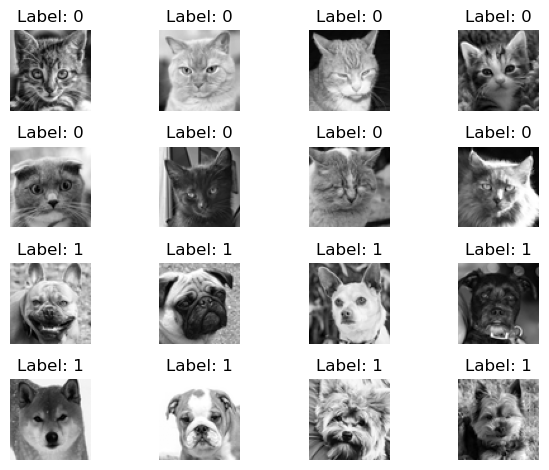

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PATHIM = "data/images.csv" 
PATHLB = "data/labels.csv"

images = pd.read_csv(PATHIM, sep=",", index_col=0)
labels = pd.read_csv(PATHLB, sep=",", index_col=0)

labels = labels.rename(columns={"0":"label"})

# Check sizes
print(f"'images' size: {images.shape}")
print(f"'labels' size: {labels.shape}")

# Number of classes:
print(f"Classes {labels["label"].unique()}")

images = np.array(images)
labels = np.array(labels).ravel()

#Visualize some images (take two from each class):
catidx = np.where(labels == 0)[0]
dogidx = np.where(labels == 1)[0]

n_samples = 8

catsample = np.random.choice(catidx, size = n_samples, replace = False)
dogsample = np.random.choice(dogidx, size = n_samples, replace = False)

idx = np.concatenate([catsample, dogsample])
images_sub = images[idx]
labels_sub = labels[idx]

fig, axes = plt.subplots(4, 4)

for i, ax in enumerate(axes.ravel()):
    img = images_sub[i].reshape(64,64)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {labels_sub[i]}")
    ax.axis("off")

plt.tight_layout()

X = images
y = labels

# Part 1

Use the provided Cats and Dogs data set.

For example, you can use filtering or wrappers in conjuction with any of the classifiers (using e.g. threshholds on the importance, t-tests/F-tests or CV-error with forward selection etc). I.e., for the filtering method you choose a test or scoring mechanism and use CV to determine the optimal threshold.

For the wrapper method you choose, e.g., forward selection or backward selection, CV is used when to stop adding features. Here, the scoring mechanism to decide which order to drop/add features can be based on drop/increase in predictive performance, importance metrics, etc.

The embedding methods we have talked about in class is lasso/elastic net which is used with multinomial/logistic regression. For the embedding methods, CV is used to choose the penalty parameter.

Note, you can also use a combination of techniques - perhaps you want to filter the features before you use wrappers or embedding methods?

Questions to answer

1. Using CV, determine how many features (pixels) you need for classification. Does the optimal number of features differ between the approaches?

2. Which pixels are selected? Does this differ between the approaches/classification methods? (Can you think of why?)

3. Repeat the above a few times - is the selection stable? (meaning the number of features needed and/or which pixels are chosen is roughly the same across multiple runs).



### Imports and global parameters

In [80]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from scipy.ndimage import gaussian_filter
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# GLOBAL PARAMETERS
BASE_SEED = 42
TEST_SIZE = 0.25
INNER_CV_FOLDS = 5
OUTER_CV_FOLDS = 4

### Defining helper functions

In [81]:
# Custom transformer for global standard scaling
class GlobalStandardScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.mean_ = X.mean()
        self.std_ = X.std()
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

# Function to generate heatmap of pixel selection frequency
def gen_heatmap(grid, X_train, y_train, inner_cv):     
        cv_results = cross_validate(
            grid.best_estimator_, X_train, y_train,
            cv=inner_cv, return_estimator=True, n_jobs=-1,
        )
        n_pixels = X_train.shape[1]
        selection_counts = np.zeros(n_pixels)

        for est in cv_results['estimator']:
            try:
                filter_idx = np.where(est.named_steps['filter'].get_support())[0]
            except:
                filter_idx = np.arange(X_train.shape[1])  # If no filter step, use all features
            try:
                embedding_idx  = filter_idx[est.named_steps['embedding'].get_support()]
            except:
                embedding_idx = filter_idx  # If no embedding step, use filter indices directly
            try:
                clf_idx = embedding_idx[est.named_steps['clf'].coef_[0] != 0]
            except:
                clf_idx = embedding_idx  # If no clf step, use embedding indices directly
            selection_counts[clf_idx] += 1

        selection_freq = selection_counts / inner_cv.n_splits
        heatmap = selection_freq.reshape(int(np.sqrt(n_pixels)), -1)

        return selection_freq, heatmap

# Function to plot heatmap of pixel selection frequency across CV folds
def plot_heatmap(heatmap):
    plt.imshow(heatmap, cmap='hot', vmin=0, vmax=1)
    plt.colorbar(label='Selection frequency across folds')
    plt.title('Pixel selection frequency across CV folds')
    plt.axis('off')
    plt.show()

# Function to add Gaussian noise to a fraction of pixels in the images    
def add_gaussian_noise(images, noise_type, noise_level, seed):
    rng = np.random.default_rng(seed)
    n_features = images.shape[1]
    side       = int(np.sqrt(n_features))
    n_noisy    = int(round(noise_level * n_features))
    noise_idx  = rng.choice(n_features, size=n_noisy, replace=False)
    images     = images.astype(float, copy=True)
    sigma      = images.std()

    if noise_type == "independent":
        ind_noise = rng.normal(0, sigma, size=(images.shape[0], n_noisy))
        images[:, noise_idx] += ind_noise

        # Pure noise pattern: one image's worth of noise, zeros elsewhere
        pure = np.zeros(n_features)
        pure[noise_idx] = ind_noise[0]
        noise_pattern = pure.reshape(side, side)

    elif noise_type == "dependent":
        raw    = rng.normal(0, sigma, size=(images.shape[0], side, side))
        smooth = gaussian_filter(raw, sigma=(0, 2, 2))
        smooth *= sigma / smooth.std()
        smooth_flat = smooth.reshape(images.shape[0], -1)
        images[:, noise_idx] += smooth_flat[:, noise_idx]

        # Pure noise pattern: one image's worth of noise, zeros elsewhere
        pure = np.zeros(n_features)
        pure[noise_idx] = smooth_flat[0][noise_idx]
        noise_pattern = pure.reshape(side, side)

    # Capture a noisy image (after noise has been applied)
    sample_noisy_image = images[0].reshape(side, side)
    return images, noise_pattern, sample_noisy_image

# Function to plot noise patterns and an example noisy image
def plot_noise_pattern(noise_type, noise_pattern, sample_noisy_image, noise_level):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(noise_pattern, cmap='gray')
    axes[0].set_title('Noise pattern')
    axes[0].axis('off')
    axes[1].imshow(sample_noisy_image, cmap='gray')
    axes[1].set_title('Example noisy image')
    axes[1].axis('off')
    fig.suptitle(f"{noise_type.capitalize()} noise applied to {100*noise_level:.0f}% of pixels", fontsize=16)
    plt.show()


### Defining model pipes

In [83]:

def model_pipes(model, seed):

    if model == "logistic":
        pipe = Pipeline([
            ('scaler', GlobalStandardScaler()),
            ('embedding', SelectFromModel(
                LogisticRegression(
                    l1_ratio=1, 
                    solver='liblinear',
                    max_iter=1000,
                    random_state=seed)
            )),
            ('clf', LogisticRegression(
                    l1_ratio=0.5, 
                    solver='saga',
                    max_iter=1000,
                    random_state=seed)
            ),
        ])

        param_grid = {
            'embedding__estimator__C': [0.05],
            'clf__C': [0.05]
        }

    elif model == "svc":
        pipe = Pipeline([
            ('scaler', GlobalStandardScaler()),
            ('filter', SelectKBest(f_classif)),
            ('embedding', SelectFromModel(
                LogisticRegression(
                    l1_ratio=1, 
                    solver='liblinear',
                    C=0.1, 
                    max_iter=1000,
                    random_state=seed)
            )),
            ('clf', LinearSVC(
                C=1.0, 
                max_iter=2000,
                random_state=seed))
        ])

        param_grid = {
            'filter__k': [1500],
            'embedding__estimator__C': [0.01, 0.05],
            'clf__C': [0.01]
        }

    elif model == "rf":
        pipe = Pipeline([
        ('filter', SelectKBest(f_classif)),
        ('clf', RandomForestClassifier(
            max_features='sqrt',
            n_jobs=-1,
            random_state=seed,
        )),
        ])

        param_grid = {
            'filter__k':           [1000],
            'clf__min_samples_leaf': [5],
            'clf__n_estimators': [100],
        }
    
    return pipe, param_grid

### Defining analysis pipeline function

In [84]:
def analysis_pipeline(images, 
                      labels, 
                      model_pipe, 
                      noise_type=None, 
                      noise_level=0, 
                      heatmap=False, 
                      votemap=False, 
                      seed=BASE_SEED):
    
    pipe, param_grid = model_pipe
    images = np.asarray(images)
    labels = np.asarray(labels)

    output = {}

    # (OPTIONAL) Corrupt a fraction of pixels with Gaussian noise
    if noise_level > 0 and noise_type is not None:
        images, noise_pattern, sample_noisy_image = add_gaussian_noise(
            images, noise_type, noise_level, seed=seed
        )
        output["noise_pattern"] = noise_pattern
        output["sample_noisy_image"] = sample_noisy_image

    # ------------------------------------------------------------------------------

    # Define the CV splitting strategy
    outer_cv = StratifiedKFold(n_splits=OUTER_CV_FOLDS, shuffle=True, random_state=seed)
    inner_cv = StratifiedKFold(n_splits=INNER_CV_FOLDS, shuffle=True, random_state=seed)

    fold_results = []
    
    for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(images, labels)):
        # Create a test and train set
        X_train, X_test = images[train_idx], images[test_idx]
        y_train, y_test = labels[train_idx], labels[test_idx]

        # Inner CV: for hyperparameter tuning
        grid = GridSearchCV(pipe, param_grid, cv=inner_cv, scoring='f1_macro', n_jobs=-1)
        grid.fit(X_train, y_train)
    
        # Score the inner-CV-selected model on the held-out outer fold
        y_pred = grid.best_estimator_.predict(X_test)

        fold_result = {
            "fold":            fold_idx,
            "best_params":     grid.best_params_,
            "inner_cv_score":  grid.best_score_,
            "outer_f1_macro":  f1_score(y_test, y_pred, average='macro'),
            "outer_accuracy":  accuracy_score(y_test, y_pred),
            "y_test":         y_test,
            "y_pred":         y_pred
        }

        # (OPTIONAL) Generate heatmap of pixel selection frequency across folds
        if heatmap:
            selection_freq, generated_heatmap = gen_heatmap(grid, X_train, y_train, inner_cv)
            fold_result['pixel_selection_frequency'] = selection_freq
            fold_result['avg_selected_pixels'] = selection_freq.sum()
            fold_result['heatmap'] = generated_heatmap
        
        fold_results.append(fold_result)

    output["fold_results"] = fold_results
    output["mean_accuracy"] = np.mean([r["outer_accuracy"]  for r in fold_results])
    output["std_accuracy"] =  np.std( [r["outer_accuracy"]  for r in fold_results])
    output["mean_f1_macro"] = np.mean([r["outer_f1_macro"]  for r in fold_results])
    output["std_f1_macro"] =  np.std( [r["outer_f1_macro"]  for r in fold_results])
    output["y_test_all"] = np.concatenate([r["y_test"] for r in fold_results])
    output["y_pred_all"] = np.concatenate([r["y_pred"] for r in fold_results])
    
    if heatmap:
        output["heatmap"] = np.mean([r["heatmap"] for r in fold_results], axis=0)
        output["pixel_selection_frequency"] = np.mean([r["pixel_selection_frequency"] for r in fold_results], axis=0)
        output["avg_selected_pixels"] = np.mean([r["avg_selected_pixels"] for r in fold_results])

    return output

### Defining function for repeated holdout (runnung analysis pipeline multiple times)

In [85]:
def repeated_holdout(images, labels, model_pipe, noise=None, noise_level=0, heatmap=False, start_seed=BASE_SEED, n_repeats=5):
    output = []
    for i in range(n_repeats):
        print("Repeat", i+1, "of", n_repeats)
        seed = start_seed + i
        result = analysis_pipeline(
            images, labels, model_pipe, 
            noise_type=noise, noise_level=noise_level, 
            heatmap=heatmap, votemap=False, 
            seed=seed
        )
        output.append(result)

    return output

### Running analysis

##### Individual runs of the three model pipes

--- Model Performance ---
              precision    recall  f1-score   support

           0       0.82      0.81      0.82      5000
           1       0.82      0.82      0.82      5000

    accuracy                           0.82     10000
   macro avg       0.82      0.82      0.82     10000
weighted avg       0.82      0.82      0.82     10000



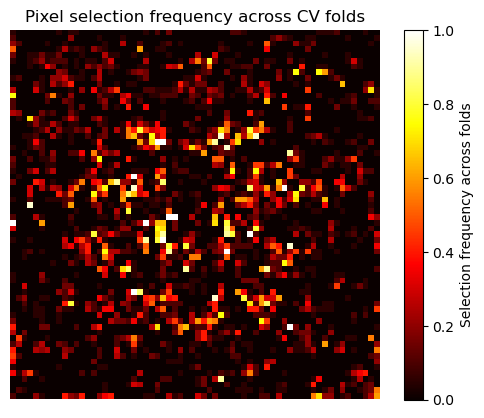

Average number of selected pixels: 319


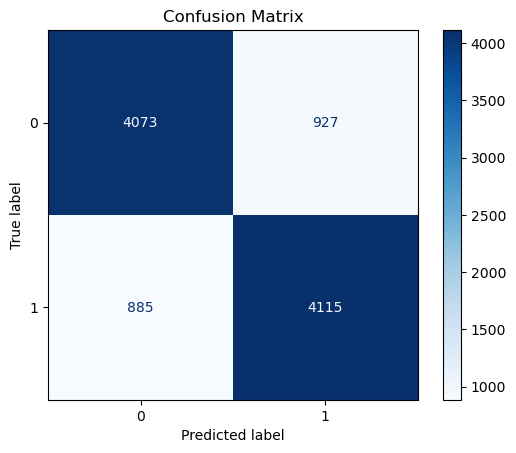

In [69]:
# Analysing LogisticRegression pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

test = analysis_pipeline(images, labels, model_pipes("logistic", seed=BASE_SEED), heatmap=True, seed=BASE_SEED)

# Evaluating best model
print("--- Model Performance ---")
print(classification_report(test["y_test_all"], test["y_pred_all"]))

plot_heatmap(test["heatmap"])
print(f"Average number of selected pixels: {test['avg_selected_pixels']:.0f}")

# # Visualize where the best model is making mistakes
ConfusionMatrixDisplay.from_predictions(test["y_test_all"], test["y_pred_all"], cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

--- Model Performance ---
              precision    recall  f1-score   support

           0       0.81      0.79      0.80      5000
           1       0.79      0.81      0.80      5000

    accuracy                           0.80     10000
   macro avg       0.80      0.80      0.80     10000
weighted avg       0.80      0.80      0.80     10000



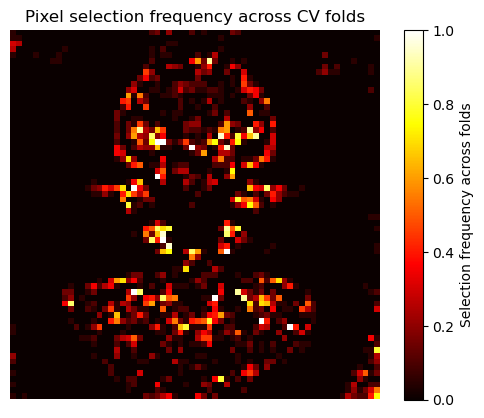

Average number of selected pixels: 196


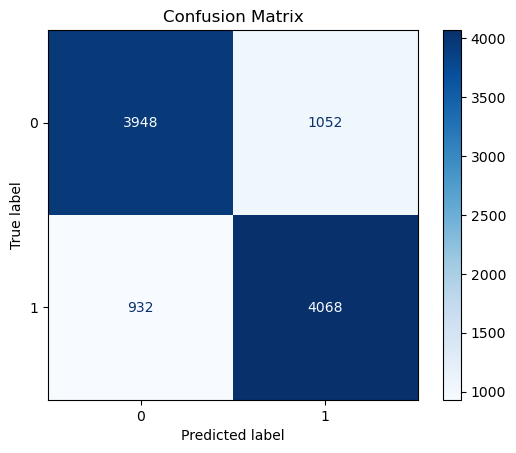

In [70]:
# Analysing SVC pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

test = analysis_pipeline(images, labels, model_pipes("svc", seed=BASE_SEED), heatmap=True, seed=BASE_SEED)

# Evaluating best model
print("--- Model Performance ---")
print(classification_report(test["y_test_all"], test["y_pred_all"]))

plot_heatmap(test["heatmap"])
print(f"Average number of selected pixels: {test['avg_selected_pixels']:.0f}")

# # Visualize where the best model is making mistakes
ConfusionMatrixDisplay.from_predictions(test["y_test_all"], test["y_pred_all"], cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

--- Model Performance ---
              precision    recall  f1-score   support

           0       0.86      0.83      0.85      5000
           1       0.84      0.86      0.85      5000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



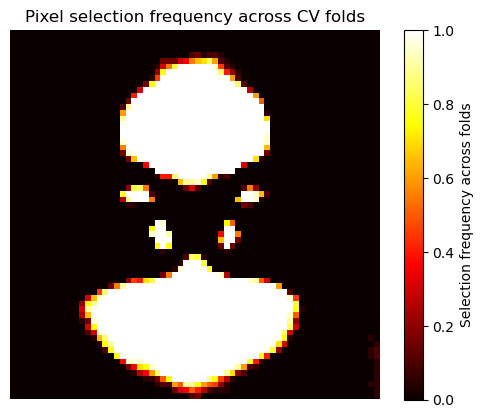

Average number of selected pixels: 1000


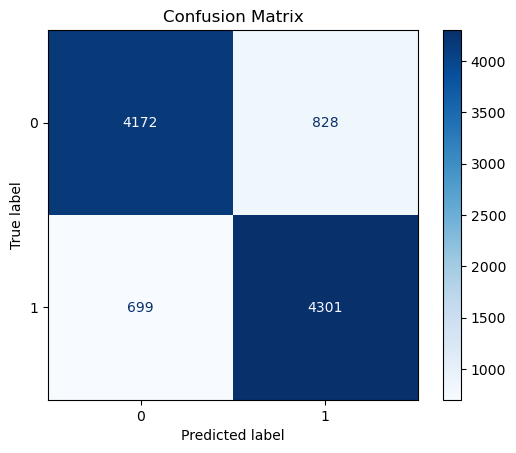

In [71]:
# Analysing RF pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

test = analysis_pipeline(images, labels, model_pipes("rf", seed=BASE_SEED), heatmap=True, seed=BASE_SEED)

# Evaluating best model
print("--- Model Performance ---")
print(classification_report(test["y_test_all"], test["y_pred_all"]))

plot_heatmap(test["heatmap"])
print(f"Average number of selected pixels: {test['avg_selected_pixels']:.0f}")

# # Visualize where the best model is making mistakes
ConfusionMatrixDisplay.from_predictions(test["y_test_all"], test["y_pred_all"], cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

##### Running repeated holdout on all three models to compare average performance


--- Evaluating LOGISTIC Pipeline ---
Mean Test Accuracy for LOGISTIC: 0.8198 ± 0.0058  (n=40 fold values)

--- Evaluating SVC Pipeline ---
Mean Test Accuracy for SVC: 0.8036 ± 0.0073  (n=40 fold values)

--- Evaluating RF Pipeline ---
Mean Test Accuracy for RF: 0.8477 ± 0.0073  (n=40 fold values)


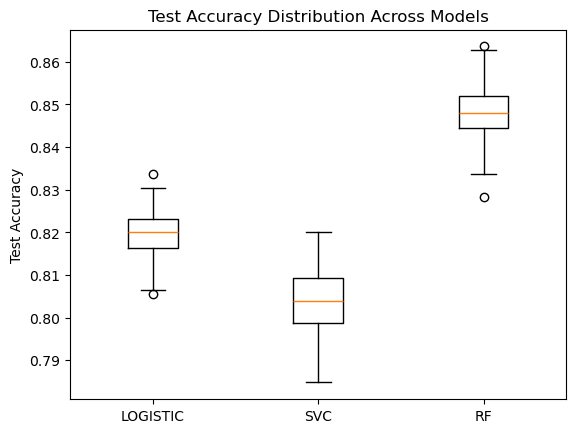

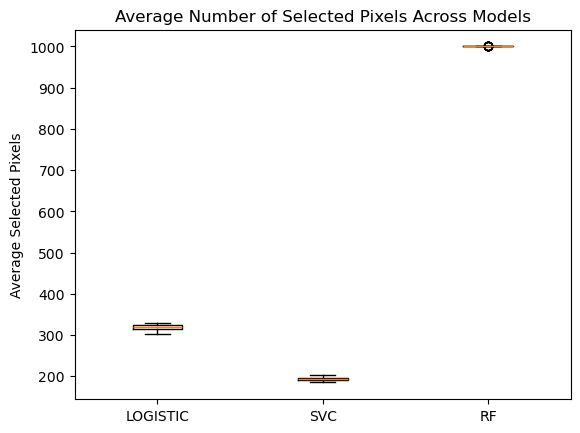

In [73]:
accuracies = {}
avg_selected_pixels = {}

for model in ["logistic", "svc", "rf"]:
    print(f"\n--- Evaluating {model.upper()} Pipeline ---")
    model_output = repeated_holdout(
        images, labels, model_pipes(model, seed=BASE_SEED),
        noise=None, heatmap=True,
        start_seed=BASE_SEED, n_repeats=10,
    )

    # Flatten every (repeat × outer fold) combination into one list
    accuracies[model] = [
        fold["outer_accuracy"]
        for result in model_output
        for fold in result["fold_results"]
    ]
    avg_selected_pixels[model] = [
        fold["avg_selected_pixels"]
        for result in model_output
        for fold in result["fold_results"]
    ]

    print(
        f"Mean Test Accuracy for {model.upper()}: "
        f"{np.mean(accuracies[model]):.4f} ± {np.std(accuracies[model]):.4f}  "
        f"(n={len(accuracies[model])} fold values)"
    )

plt.boxplot(
    [accuracies[m] for m in accuracies],
    tick_labels=[m.upper() for m in accuracies],
)
plt.title("Test Accuracy Distribution Across Models")
plt.ylabel("Test Accuracy")
plt.show()

plt.boxplot(
    [avg_selected_pixels[m] for m in avg_selected_pixels],
    tick_labels=[m.upper() for m in avg_selected_pixels],
)
plt.title("Average Number of Selected Pixels Across Models")
plt.ylabel("Average Selected Pixels")
plt.show()

## Part 2 - Correlated noise features
Use the Cats and Dogs data set. 

Add (independent) Gaussian noise to a subset of the features. Increase the percentage of the features. 
How is classification accuracy affected for the different methods?

Now, do the same but with correlated Gaussian noise. 
How do the different methods handle correlated noise features? 
At what noise level do the methods break down? 

### Testing different levels of independent noise


--- Evaluating LOGISTIC Pipeline ---
Noise level: 0.25
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.25: Acc 0.8015 ± 0.0075, Pixels 619
Noise level: 0.50
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.50: Acc 0.7944 ± 0.0050, Pixels 827
Noise level: 0.75
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.75: Acc 0.7849 ± 0.0061, Pixels 979
Noise level: 1.00
Repeat 1 of 2
Repeat 2 of 2
  Noise 1.00: Acc 0.7662 ± 0.0070, Pixels 1100

--- Evaluating SVC Pipeline ---
Noise level: 0.25
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.25: Acc 0.7981 ± 0.0032, Pixels 224
Noise level: 0.50
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.50: Acc 0.7948 ± 0.0083, Pixels 198
Noise level: 0.75
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.75: Acc 0.7917 ± 0.0098, Pixels 167
Noise level: 1.00
Repeat 1 of 2
Repeat 2 of 2
  Noise 1.00: Acc 0.7800 ± 0.0027, Pixels 208

--- Evaluating RF Pipeline ---
Noise level: 0.25
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.25: Acc 0.8435 ± 0.0070, Pixels 1000
Noise level: 0.50
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.50: Acc 0.8

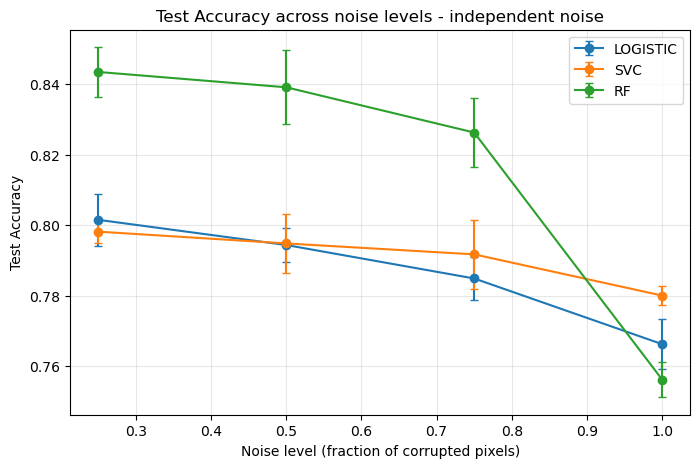

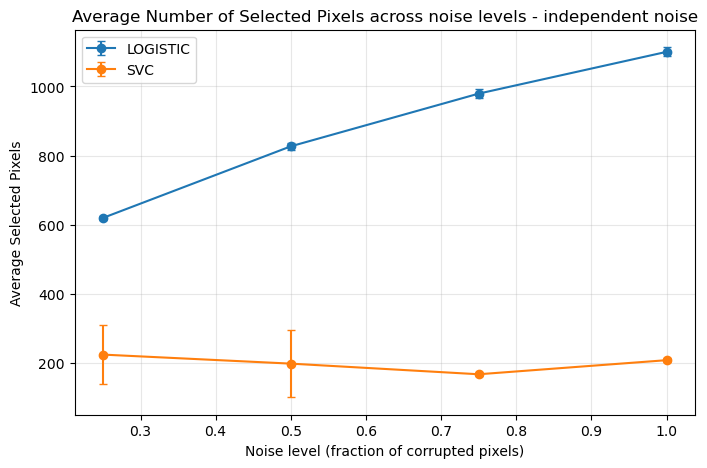

In [87]:
noise_levels = [0.25, 0.5, 0.75, 1.0]
models = ["logistic", "svc", "rf"]

accuracies = {m: [] for m in models}
accuracies_std = {m: [] for m in models}
selected_pixels = {m: [] for m in models}
selected_pixels_std = {m: [] for m in models}

for model in models:
    print(f"\n--- Evaluating {model.upper()} Pipeline ---")
    for noise_level in noise_levels:
        print(f"Noise level: {noise_level:.2f}")
        model_output = repeated_holdout(
            images, labels, model_pipes(model, seed=BASE_SEED),
            noise="independent", noise_level=noise_level,
            heatmap=True, start_seed=BASE_SEED, n_repeats=2,
        )

        # Flatten across (repeat × outer fold) → one value per fold
        fold_accs = [
            fold["outer_accuracy"]
            for result in model_output
            for fold in result["fold_results"]
        ]
        fold_pixels = [
            fold["avg_selected_pixels"]
            for result in model_output
            for fold in result["fold_results"]
        ]

        accuracies[model].append(np.mean(fold_accs))
        accuracies_std[model].append(np.std(fold_accs))
        selected_pixels[model].append(np.mean(fold_pixels))
        selected_pixels_std[model].append(np.std(fold_pixels))

        print(f"  Noise {noise_level:.2f}: "
              f"Acc {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}, "
              f"Pixels {np.mean(fold_pixels):.0f}")

# --- Accuracy vs noise level ---
plt.figure(figsize=(8, 5))
for m in models:
    plt.errorbar(noise_levels, accuracies[m], yerr=accuracies_std[m],
                 marker='o', capsize=3, label=m.upper())
plt.title("Test Accuracy across noise levels - independent noise")
plt.xlabel("Noise level (fraction of corrupted pixels)")
plt.ylabel("Test Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# --- Avg selected pixels vs noise level ---
plt.figure(figsize=(8, 5))
for m in ["logistic", "svc"]:
    plt.errorbar(noise_levels, selected_pixels[m], yerr=selected_pixels_std[m],
                 marker='o', capsize=3, label=m.upper())
plt.title("Average Number of Selected Pixels across noise levels - independent noise")
plt.xlabel("Noise level (fraction of corrupted pixels)")
plt.ylabel("Average Selected Pixels")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Testing different levels of dependent noise


--- Evaluating LOGISTIC Pipeline ---
Noise level: 0.25
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.25: Acc 0.8142 ± 0.0065, Pixels 408
Noise level: 0.50
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.50: Acc 0.8132 ± 0.0062, Pixels 382
Noise level: 0.75
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.75: Acc 0.8127 ± 0.0051, Pixels 347
Noise level: 1.00
Repeat 1 of 2
Repeat 2 of 2
  Noise 1.00: Acc 0.7330 ± 0.0060, Pixels 302

--- Evaluating SVC Pipeline ---
Noise level: 0.25
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.25: Acc 0.8007 ± 0.0059, Pixels 223
Noise level: 0.50
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.50: Acc 0.8061 ± 0.0081, Pixels 217
Noise level: 0.75
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.75: Acc 0.8002 ± 0.0067, Pixels 203
Noise level: 1.00
Repeat 1 of 2
Repeat 2 of 2
  Noise 1.00: Acc 0.7271 ± 0.0059, Pixels 131

--- Evaluating RF Pipeline ---
Noise level: 0.25
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.25: Acc 0.8439 ± 0.0084, Pixels 1000
Noise level: 0.50
Repeat 1 of 2
Repeat 2 of 2
  Noise 0.50: Acc 0.83

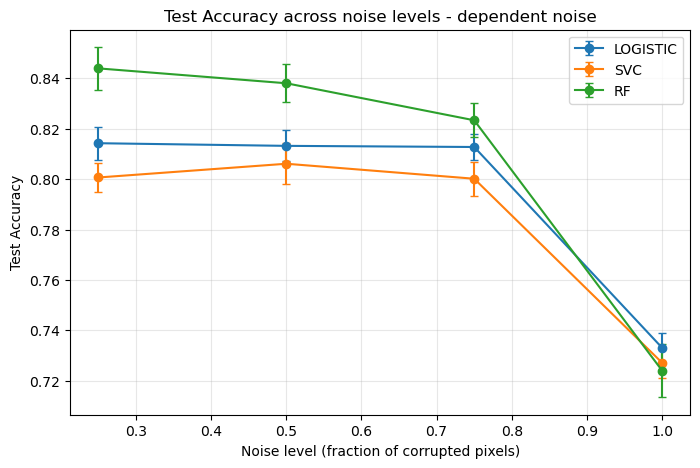

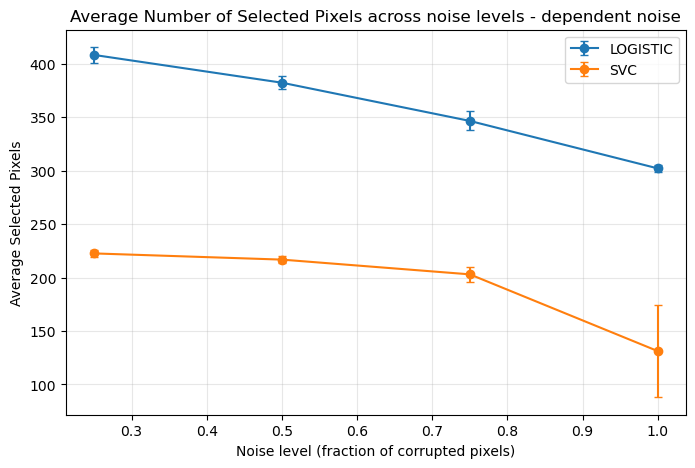

In [89]:
noise_levels = [0.25, 0.5, 0.75, 1.0]
models = ["logistic", "svc", "rf"]

accuracies = {m: [] for m in models}
accuracies_std = {m: [] for m in models}
selected_pixels = {m: [] for m in models}
selected_pixels_std = {m: [] for m in models}

for model in models:
    print(f"\n--- Evaluating {model.upper()} Pipeline ---")
    for noise_level in noise_levels:
        print(f"Noise level: {noise_level:.2f}")
        model_output = repeated_holdout(
            images, labels, model_pipes(model, seed=BASE_SEED),
            noise="dependent", noise_level=noise_level,
            heatmap=True, start_seed=BASE_SEED, n_repeats=2,
        )

        # Flatten across (repeat × outer fold) → one value per fold
        fold_accs = [
            fold["outer_accuracy"]
            for result in model_output
            for fold in result["fold_results"]
        ]
        fold_pixels = [
            fold["avg_selected_pixels"]
            for result in model_output
            for fold in result["fold_results"]
        ]

        accuracies[model].append(np.mean(fold_accs))
        accuracies_std[model].append(np.std(fold_accs))
        selected_pixels[model].append(np.mean(fold_pixels))
        selected_pixels_std[model].append(np.std(fold_pixels))

        print(f"  Noise {noise_level:.2f}: "
              f"Acc {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}, "
              f"Pixels {np.mean(fold_pixels):.0f}")

# --- Accuracy vs noise level ---
plt.figure(figsize=(8, 5))
for m in models:
    plt.errorbar(noise_levels, accuracies[m], yerr=accuracies_std[m],
                 marker='o', capsize=3, label=m.upper())
plt.title("Test Accuracy across noise levels - dependent noise")
plt.xlabel("Noise level (fraction of corrupted pixels)")
plt.ylabel("Test Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# --- Avg selected pixels vs noise level ---
plt.figure(figsize=(8, 5))
for m in ["logistic", "svc"]:
    plt.errorbar(noise_levels, selected_pixels[m], yerr=selected_pixels_std[m],
                 marker='o', capsize=3, label=m.upper())
plt.title("Average Number of Selected Pixels across noise levels - dependent noise")
plt.xlabel("Noise level (fraction of corrupted pixels)")
plt.ylabel("Average Selected Pixels")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

'images' size: (10000, 4096)
'labels' size: (10000, 1)
Classes [0 1]


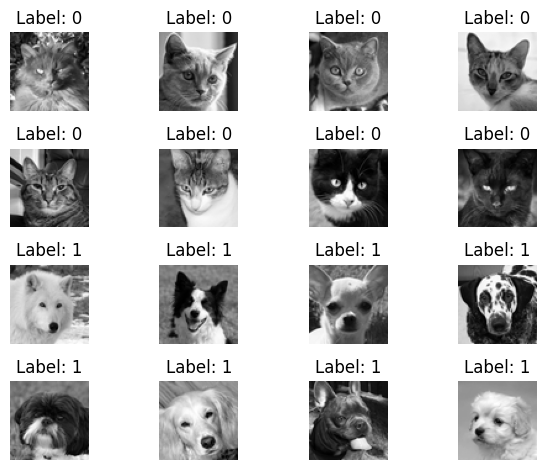

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PATHIM = "/Users/viggo/MVE441/cnd_large/images.csv" 
PATHLB = "/Users/viggo/MVE441/cnd_large/labels.csv"

images = pd.read_csv(PATHIM, sep=",", index_col=0)
labels = pd.read_csv(PATHLB, sep=",", index_col=0)

labels = labels.rename(columns={"0":"label"})

# Check sizes
print(f"'images' size: {images.shape}")
print(f"'labels' size: {labels.shape}")

# Number of classes:
print(f"Classes {labels["label"].unique()}")

images = np.array(images)
labels = np.array(labels).ravel()

#Visualize some images (take two from each class):
catidx = np.where(labels == 0)[0]
dogidx = np.where(labels == 1)[0]

n_samples = 8

catsample = np.random.choice(catidx, size = n_samples, replace = False)
dogsample = np.random.choice(dogidx, size = n_samples, replace = False)

idx = np.concatenate([catsample, dogsample])
images_sub = images[idx]
labels_sub = labels[idx]

fig, axes = plt.subplots(4, 4)

for i, ax in enumerate(axes.ravel()):
    img = images_sub[i].reshape(64,64)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {labels_sub[i]}")
    ax.axis("off")

plt.tight_layout()

X = images
y = labels

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin


class GlobalStandardScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.mean_ = X.mean()
        self.std_ = X.std()
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

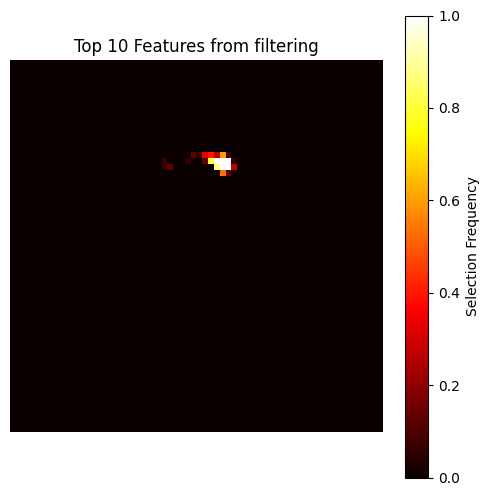

k=10: Average CV Accuracy = 0.6462


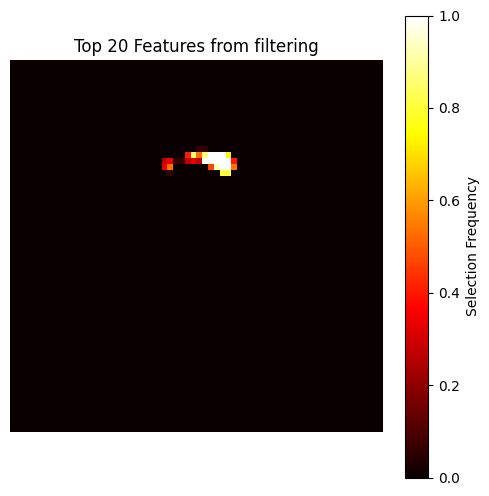

k=20: Average CV Accuracy = 0.6507


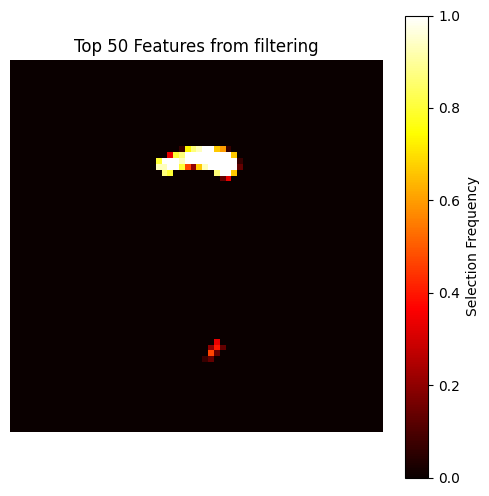

k=50: Average CV Accuracy = 0.6781


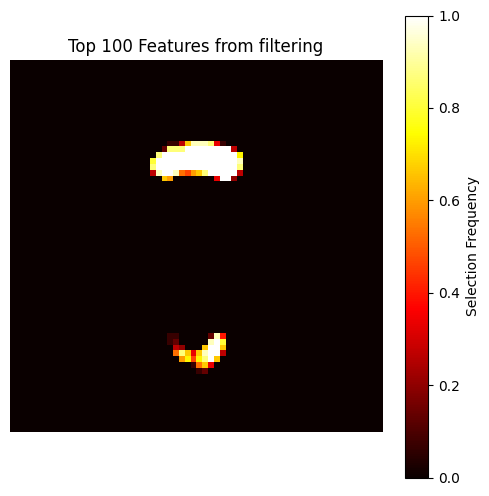

k=100: Average CV Accuracy = 0.7120


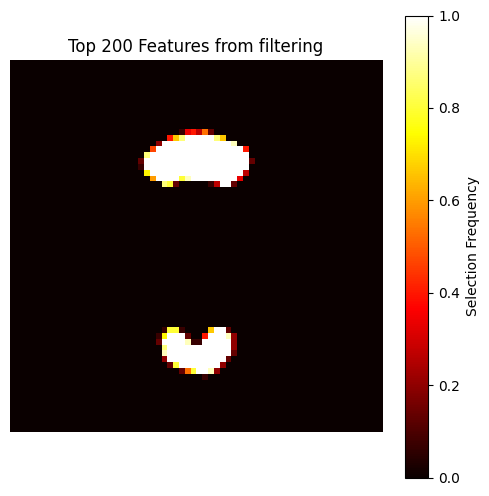

k=200: Average CV Accuracy = 0.7196
Best k: 200 with CV Accuracy = 0.7196
summary of results:
k=10: 0.6462 | folds=[0.6467 0.6527 0.64   0.6453 0.662  0.6713 0.6367 0.6533 0.628  0.6433
 0.63   0.652  0.6447 0.646  0.6407]
k=20: 0.6507 | folds=[0.656  0.654  0.6493 0.6487 0.662  0.668  0.6447 0.666  0.6407 0.65
 0.6347 0.6533 0.6393 0.6527 0.6407]
k=50: 0.6781 | folds=[0.664  0.688  0.652  0.6993 0.6567 0.714  0.6407 0.6633 0.6393 0.6533
 0.6827 0.7033 0.7153 0.708  0.692 ]
k=100: 0.7120 | folds=[0.708  0.7187 0.7127 0.7147 0.712  0.72   0.7227 0.7053 0.714  0.7073
 0.692  0.72   0.7233 0.716  0.6933]
k=200: 0.7196 | folds=[0.7093 0.7267 0.7213 0.7073 0.7233 0.738  0.7287 0.7107 0.7253 0.726
 0.7073 0.722  0.726  0.7207 0.702 ]


/var/folders/hn/3_40yr6s0bx280zl0j62jsvm0000gn/T/ipykernel_46067/3058734052.py:84: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(boxplot_data, labels=k_values, showmeans=True)


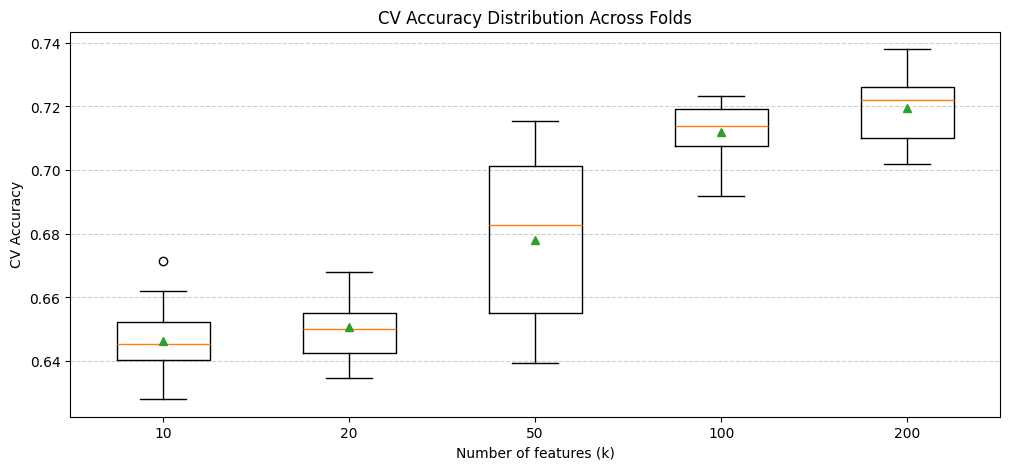

In [ ]:
import numpy as np
from sklearn.feature_selection import SelectKBest, f_classif # used for feature selection (ANOVA F-test)
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

k_values = [10, 20, 50, 100, 200] #, 300, 400, 500, 600, 700, 800, 900, 1000] # different values of k (features) to test
#cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
selected_features = {k: [] for k in k_values}
fold_results_filtering = {k: [] for k in k_values}  # store all fold accuracies for each k

#scaler = StandardScaler()
scaler = GlobalStandardScaler()  # custom scaler that standardizes globally across all features

cv_seeds = [101, 202, 303]  # different seeds for CV to get more stable estimate of performance

for k in k_values:
    selected_features[k] = []  # reset for this k

    # Perform CV for this k
    # Loop over three CV seeds to get more stable estimate of performance 
    for seed in cv_seeds:

        X_train, X_test, y_train, y_test = train_test_split(images, labels, 
                                                        random_state=seed, test_size=0.25, stratify=labels)

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

        for train_idx, val_idx in cv.split(X_train, y_train):
            X_train_fold = X_train[train_idx]
            y_train_fold = y_train[train_idx]
            X_val_fold = X_train[val_idx]
            y_val_fold = y_train[val_idx]

            X_train_scaled = scaler.fit_transform(X_train_fold)
            X_val_scaled = scaler.transform(X_val_fold)

            # Feature selection (ANOVA F-test)
            selector = SelectKBest(f_classif, k=k)
            X_train_sel = selector.fit_transform(X_train_scaled, y_train_fold)
            X_val_sel = selector.transform(X_val_scaled)

            top_k_indices = selector.get_support(indices=True) # get indices of selected features
            selected_features[k].append(top_k_indices) # store selected features for this fold for plotting later

            # Train classifier
            model = LogisticRegression(max_iter=1000, penalty="l2", solver="lbfgs", random_state=42)
            model.fit(X_train_sel, y_train_fold)

            # Validate
            y_pred = model.predict(X_val_sel)
            acc = accuracy_score(y_val_fold, y_pred)
            fold_results_filtering[k].append(acc)

    """ Plot heatmap of feature selection frequency across folds for this k """
    feature_image = np.zeros(64*64)
    for features in selected_features[k]:
        feature_image[features] += 1  # Increment count for selected features
    feature_image /= cv.get_n_splits()*len(cv_seeds)  # Normalize by number of folds x number of seeds to get average selection frequency
    plt.figure(figsize=(6, 6))
    plt.imshow(feature_image.reshape(64, 64), cmap="hot")
    plt.colorbar(label="Selection Frequency")
    plt.title(f"Top {k} Features from filtering")
    plt.axis("off")
    plt.show()

    results[k] = np.mean(fold_results_filtering[k])
    print(f"k={k}: Average CV Accuracy = {results[k]:.4f}")

best_k = max(results, key=results.get)
print(f"Best k: {best_k} with CV Accuracy = {results[best_k]:.4f}")
print("summary of results:")
for k, acc in results.items():
    print(f"k={k}: {acc:.4f} | folds={np.round(fold_results_filtering[k], 4)}")

""" Boxplot of fold accuracies for each k """
plt.figure(figsize=(12, 5))
boxplot_data = [fold_results_filtering[k] for k in k_values]
plt.boxplot(boxplot_data, labels=k_values, showmeans=True)
plt.xlabel("Number of features (k)")
plt.ylabel("CV Accuracy")
plt.title("CV Accuracy Distribution Across Folds")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


## Wrapping feature selection

OBS: this takes a looooong time to run :(

Running wrapper for 20 features...
  CV seed: 100
  CV seed: 200
  CV seed: 300
20 features → mean CV accuracy on Logistic Regression: 0.7182, Time: 6.06 minutes
20 features → mean CV accuracy on Random Forest: 0.7543, Time: 6.06 minutes
Selected feature indices (reduced space) for n_features=20:
  Seed 1: [  4   7  11  13  15  36  37  39  41  42  68  69  71 143 147 151 152 160
 161 198]
  Seed 2: [  4   5  18  45  51  63  68  70  75  77  82  95  96 118 134 140 150 157
 164 165]
  Seed 3: [  5  24  32  49  63  69  78  82  97  99 107 125 145 149 150 156 162 164
 173 182]


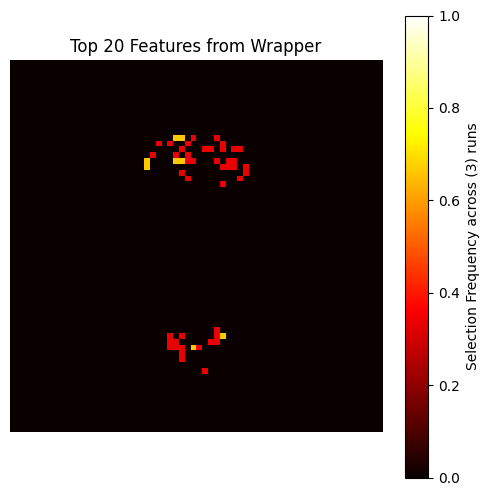

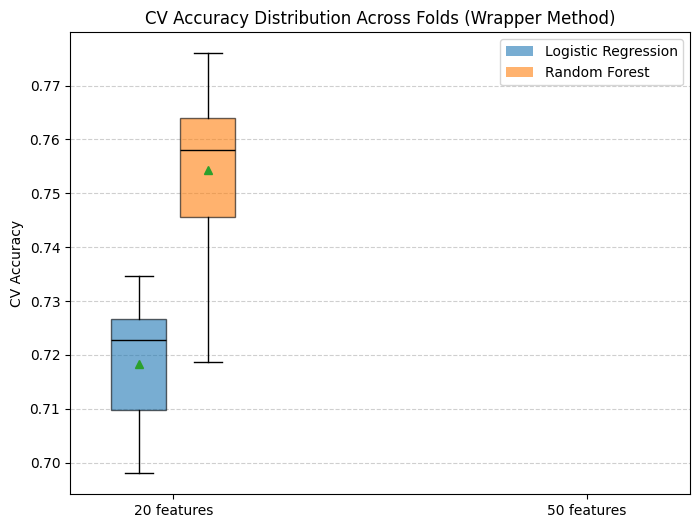

Running wrapper for 50 features...
  CV seed: 100
  CV seed: 200
  CV seed: 300
50 features → mean CV accuracy on Logistic Regression: 0.7206, Time: 28.08 minutes
50 features → mean CV accuracy on Random Forest: 0.7733, Time: 28.08 minutes
Selected feature indices (reduced space) for n_features=50:
  Seed 1: [  3   4   5   7  10  11  12  13  15  17  19  20  22  25  26  31  32  34
  36  37  39  41  42  43  53  55  60  68  69  70  71  75  80  93 110 118
 128 129 134 143 144 147 151 152 154 160 161 164 195 198]
  Seed 2: [  4   5   6  12  18  24  26  33  44  45  46  47  48  51  63  64  65  68
  70  74  75  77  82  83  88  92  95  96 100 101 106 108 113 114 118 127
 130 131 134 138 140 141 149 150 151 157 161 164 165 166]
  Seed 3: [  0   1   4   5  12  14  16  24  25  26  32  38  40  41  42  44  46  49
  50  59  60  62  63  64  69  78  82  84  97  99 100 103 107 120 125 134
 145 148 149 150 154 156 162 164 165 173 174 182 190 197]


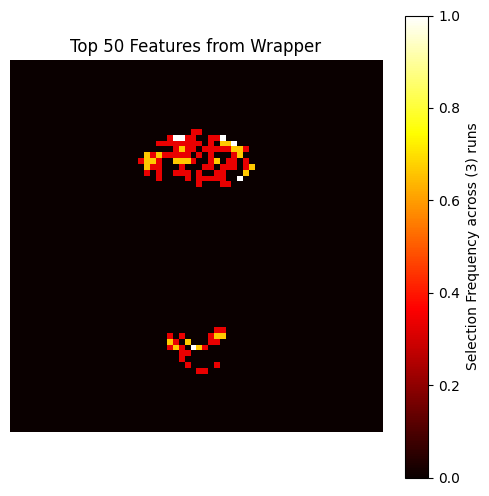

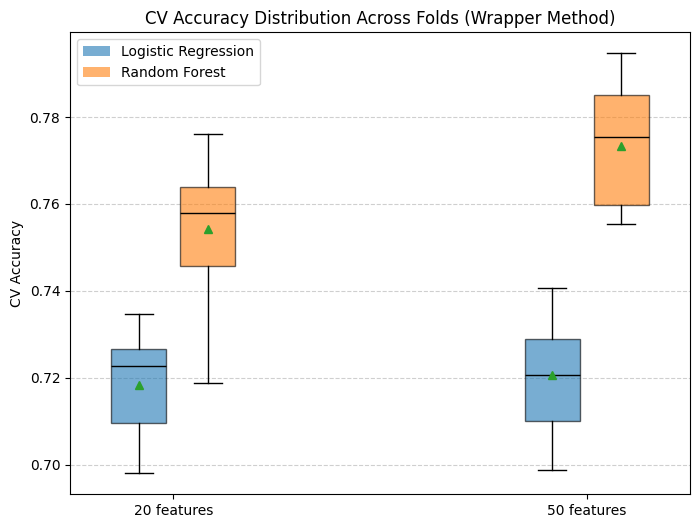

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import tqdm 
import time 
import warnings
from matplotlib.patches import Patch    
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore", category=UserWarning)  # suppress warnings from sklearn about convergence

""" Analyze wrapper method for feature selection using Sequential Feature Selector (SFS) from sklearn.
We will test different values of n_features to select and evaluate performance on both Logistic Regression and Random Forest classifiers. 
We will also visualize the selected features as heatmaps and boxplots of fold accuracies"""

cv_seeds = [100, 200, 300]  # different seeds for CV to get more stable estimate of performance

feature_counts = [20, 50] # , 20, 50] # different values of n_features to test for wrapper method

wrapper_results_LR = {}
fold_results_wrapper_LR = {n: [] for n in feature_counts}  # store all fold accuracies for each n_features

wrapper_results_RF = {}
fold_results_wrapper_RF = {n: [] for n in feature_counts}  # store all fold accuracies for each n_features

selected_features_wrapper = {n: [] for n in feature_counts}
feature_mappings = {n: [] for n in feature_counts}

n_samples = 2000  # reduce number of samples for wrapper method to speed up computation
candidate_features = 200 # number of candidate features to consider for wrapper method (take top 100 from filtering step to speed up wrapper method)

# use the actual label array `y` (not the plotting `labels` list)
X_train, X_test, y_train, y_test = train_test_split(images, y,
                                                    random_state=42, test_size=0.25, stratify=y)

for n_features in feature_counts:
    print(f"Running wrapper for {n_features} features...")
    start_time = time.time()

    for seed in cv_seeds:
        print(f"  CV seed: {seed}")
        cv_select = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
        cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

        # take top 200 features by filtering and store the selector for later mapping
        original_selector = SelectKBest(f_classif, k=candidate_features)
        X_reduced = original_selector.fit_transform(X_train, y_train)

        # store mapping of reduced features to original features for later visualization
        mapping = original_selector.get_support(indices=True)
        feature_mappings[n_features].append(mapping)

        # reduce number of samples to speed up wrapper method (since it's much more computationally expensive than filtering)
        rng = np.random.default_rng(seed)
        subset_idx = rng.choice(len(X_reduced), size=n_samples, replace=False)

        X_small = X_reduced[subset_idx]
        y_small = y_train[subset_idx]


        model_selection = LogisticRegression(max_iter=1000, penalty="l2", solver="lbfgs", random_state=seed)
        model_evaluation_LR = LogisticRegression(max_iter=1000, penalty="l2", solver="lbfgs", random_state=seed)
        model_evaluation_RF = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1)

        sfs = SequentialFeatureSelector(
            model_selection,
            n_features_to_select=n_features,
            direction="forward",
            scoring="accuracy",
            cv=cv_select,
            n_jobs=-1
        )

        sfs.fit(X_small, y_small) # fit on the small subset to speed up wrapper method

        selected_idx = sfs.get_support(indices=True)
        selected_features_wrapper[n_features].append(selected_idx)  # store selected features for this fold for plotting later

        # Evaluate using CV again
        fold_acc_LR = []
        fold_acc_RF = []

        for train_idx, val_idx in cv_eval.split(X_reduced, y_train):
            X_tr = X_reduced[train_idx][:, selected_idx]
            X_val = X_reduced[val_idx][:, selected_idx]

            y_tr = y_train[train_idx]
            y_val = y_train[val_idx]

            # evaluate on Logistic Regression
            model_evaluation_LR.fit(X_tr, y_tr) # fit on the full training data with selected features
            acc_LR = model_evaluation_LR.score(X_val, y_val)
            fold_results_wrapper_LR[n_features].append(acc_LR)  # store fold accuracy for this n_features
            fold_acc_LR.append(acc_LR)

            # evaluate on Random Forest
            model_evaluation_RF.fit(X_tr, y_tr)
            acc_RF = model_evaluation_RF.score(X_val, y_val)
            fold_results_wrapper_RF[n_features].append(acc_RF)  # store fold accuracy for this n_features
            fold_acc_RF.append(acc_RF)


    wrapper_results_LR[n_features] = np.mean(fold_results_wrapper_LR[n_features])
    wrapper_results_RF[n_features] = np.mean(fold_results_wrapper_RF[n_features])
    end_time = time.time()
    print(f"{n_features} features → mean CV accuracy on Logistic Regression: {wrapper_results_LR[n_features]:.4f}, Time: {(end_time - start_time)/60:.2f} minutes")
    print(f"{n_features} features → mean CV accuracy on Random Forest: {wrapper_results_RF[n_features]:.4f}, Time: {(end_time - start_time)/60:.2f} minutes")

    # print selected features for this n_features
    print(f"Selected feature indices (reduced space) for n_features={n_features}:")
    for seed_idx, features in enumerate(selected_features_wrapper[n_features]):
        print(f"  Seed {seed_idx+1}: {features}")

    # Create heatmap: map wrapper-selected indices back to original 64x64 image space
    feature_image = np.zeros(64*64, dtype=float)
    for run_idx, reduced_idx in enumerate(selected_features_wrapper[n_features]):
        mapping = feature_mappings[n_features][run_idx] # get mapping for this run
        original_idx = mapping[reduced_idx] # map back to original feature index
        feature_image[original_idx] += 1 # Increment count for selected features
    
    feature_image /= len(cv_seeds)  # Normalize by number of seeds to get average selection frequency
    plt.figure(figsize=(6, 6))
    im = plt.imshow(feature_image.reshape(64, 64), cmap="hot", vmin=0, vmax=1)

    plt.colorbar(im, label="Selection Frequency across (3) runs")
    #plt.imshow(feature_image.reshape(64, 64), cmap="hot")
    plt.title(f"Top {n_features} Features from Wrapper")
    plt.axis("off")
    plt.show()

    # one figure with grouped boxplots for LR and RF
    plt.figure(figsize=(8, 6))

    data = []
    positions = []
    colors = []

    gap = 1.5
    base_positions = np.arange(len(feature_counts)) * gap * 2 + 1

    for i, n in enumerate(feature_counts):
        data.append(fold_results_wrapper_LR[n])
        positions.append(base_positions[i] - 0.25)
        colors.append("tab:blue")

        data.append(fold_results_wrapper_RF[n])
        positions.append(base_positions[i] + 0.25)
        colors.append("tab:orange")

    bp = plt.boxplot(data, positions=positions, widths=0.4, patch_artist=True, showmeans=True)

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    for median in bp["medians"]:
        median.set_color("black")

    plt.xticks(base_positions, [f"{n} features" for n in feature_counts])
    #plt.xlabel("Number of features (n)")
    plt.ylabel("CV Accuracy")
    plt.title("CV Accuracy Distribution Across Folds (Wrapper Method)")
    plt.grid(axis="y", linestyle="--", alpha=0.6)

    plt.legend(
        handles=[
            Patch(facecolor="tab:blue", alpha=0.6, label="Logistic Regression"),
            Patch(facecolor="tab:orange", alpha=0.6, label="Random Forest"),
        ],
        loc="best",
    )

    plt.show()

# make final unbiased evaluation on test set using n_features from wrapper method for both LR and RF based on CV performance,
# and compare to filtering method with same n_features on test set



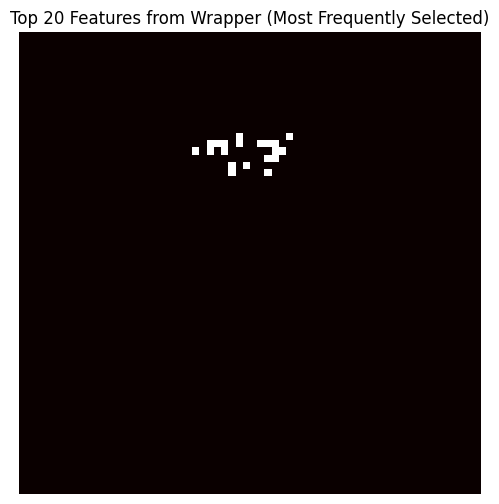

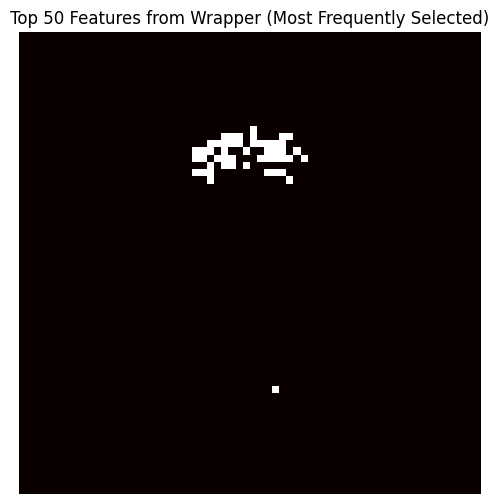

In [ ]:
selected_20_wrapper = selected_features_wrapper[20]
selected_50_wrapper = selected_features_wrapper[50]

# get the most frequently selected features across folds for 20 and 50 feature cases
from collections import Counter
def get_top_features(selected_features_list, top_n=20):
    all_selected = np.concatenate(selected_features_list)
    feature_counts = Counter(all_selected)
    most_common = feature_counts.most_common(top_n)
    return [idx for idx, count in most_common]

top_20_wrapper = get_top_features(selected_20_wrapper, top_n=20)
top_50_wrapper = get_top_features(selected_50_wrapper, top_n=50)

original_feature_indices = feature_mappings[20][0]  # mapping from reduced space to original space (same for all runs since we use the same original selector)


# Map back to original feature indices for visualization
top_20_original = original_feature_indices[top_20_wrapper]
top_50_original = original_feature_indices[top_50_wrapper]

# Create heatmaps for top 20 and top 50 features from wrapper method
def plot_feature_heatmap(feature_indices, title):
    feature_image = np.zeros(64*64, dtype=float)
    feature_image[feature_indices] = 1  # Mark selected features
    plt.figure(figsize=(6, 6))
    im = plt.imshow(feature_image.reshape(64, 64), cmap="hot", vmin=0, vmax=1)
    #plt.colorbar(im, label="Selected (1) vs Not Selected (0)")
    plt.title(title)
    plt.axis("off")
    plt.show()

plot_feature_heatmap(top_20_original, "Top 20 Features from Wrapper (Most Frequently Selected)")
plot_feature_heatmap(top_50_original, "Top 50 Features from Wrapper (Most Frequently Selected)")

## Compare selection strategies on RF

Filtering 20 features: mean RF CV accuracy = 0.7143
Filtering 50 features: mean RF CV accuracy = 0.7257
Filtering 200 features: mean RF CV accuracy = 0.7993
Wrapper 20 features: mean RF CV accuracy = 0.7416
Wrapper 50 features: mean RF CV accuracy = 0.7715


/var/folders/hn/3_40yr6s0bx280zl0j62jsvm0000gn/T/ipykernel_46067/4173973256.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(boxplot_data, labels=labels, showmeans=False)


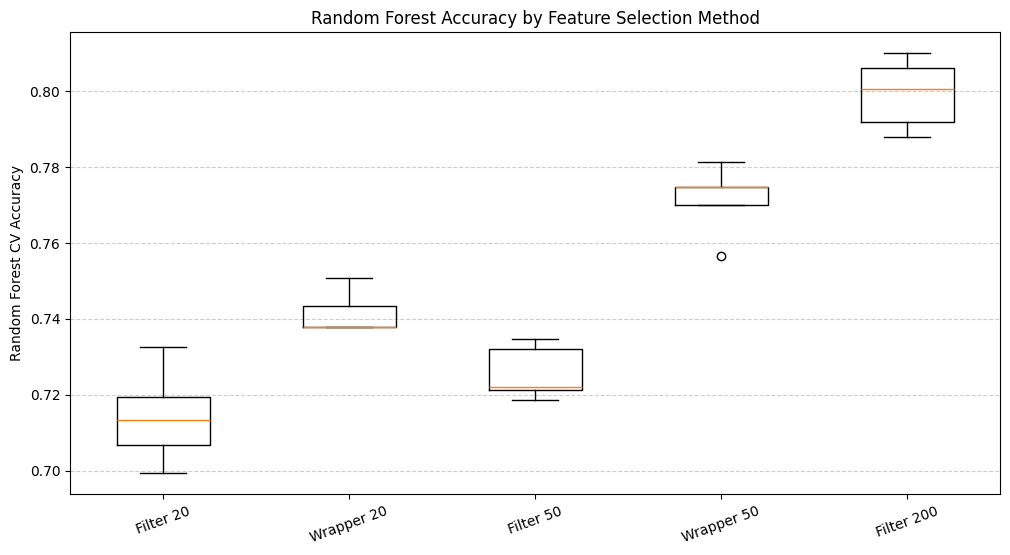

Wrapper 20 features → Test Accuracy: LR=0.6928, RF=0.7244
Filtering 20 features → Test Accuracy: LR=0.6508, RF=0.7092
Wrapper 50 features → Test Accuracy: LR=0.7060, RF=0.7548
Filtering 50 features → Test Accuracy: LR=0.6536, RF=0.7212


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=420)

filtering_feature_counts = [20, 50, 200]
wrapper_feature_counts = [20, 50]


def most_frequent_features(feature_lists, n_features, original_space_size=64 * 64):
    feature_counts = np.zeros(original_space_size, dtype=int)
    for features in feature_lists:
        feature_counts[features] += 1
    return np.argsort(feature_counts)[-n_features:]


# Build stable feature sets from filtering results in original 64x64 space
filtering_selected_sets = {}
for k in filtering_feature_counts:
    filtering_selected_sets[k] = most_frequent_features(selected_features[k], k)

# Build stable feature sets from wrapper results in original 64x64 space
wrapper_selected_sets = {}
for n_features in wrapper_feature_counts:
    wrapper_counts = np.zeros(64 * 64, dtype=int)
    for run_idx, reduced_selected in enumerate(selected_features_wrapper[n_features]):
        mapping = feature_mappings[n_features][run_idx]
        original_selected = mapping[reduced_selected]
        wrapper_counts[original_selected] += 1
    wrapper_selected_sets[n_features] = np.argsort(wrapper_counts)[-n_features:] # get top n_features most frequently selected in original space


# Evaluate random forest with CV on each feature set
rf_results = {
    "Filtering": {},
    "Wrapper": {},
}


for k in filtering_feature_counts:
    fold_acc = []
    selected_idx = filtering_selected_sets[k]

    for train_idx, val_idx in rf_cv.split(X_train, y_train):
        X_tr = X_train[train_idx][:, selected_idx]
        X_val = X_train[val_idx][:, selected_idx]
        y_tr = y_train[train_idx]
        y_val = y_train[val_idx]

        rf.fit(X_tr, y_tr)
        fold_acc.append(rf.score(X_val, y_val))

    rf_results["Filtering"][k] = fold_acc
    print(f"Filtering {k} features: mean RF CV accuracy = {np.mean(fold_acc):.4f}")

for n_features in wrapper_feature_counts:
    fold_acc = []
    selected_idx = wrapper_selected_sets[n_features]

    for train_idx, val_idx in rf_cv.split(X_train, y_train):
        X_tr = X_train[train_idx][:, selected_idx]
        X_val = X_train[val_idx][:, selected_idx]
        y_tr = y_train[train_idx]
        y_val = y_train[val_idx]

        rf.fit(X_tr, y_tr)
        fold_acc.append(rf.score(X_val, y_val))

    rf_results["Wrapper"][n_features] = fold_acc
    print(f"Wrapper {n_features} features: mean RF CV accuracy = {np.mean(fold_acc):.4f}")


# Boxplot comparison
boxplot_data = [
    rf_results["Filtering"][20],
    rf_results["Wrapper"][20],
    rf_results["Filtering"][50],
    rf_results["Wrapper"][50],
    rf_results["Filtering"][200],
]
labels = [
    "Filter 20",
    "Wrapper 20",
    "Filter 50",
    "Wrapper 50",
    "Filter 200",
]

plt.figure(figsize=(12, 6))
plt.boxplot(boxplot_data, labels=labels, showmeans=False)
plt.ylabel("Random Forest CV Accuracy")
plt.title("Random Forest Accuracy by Feature Selection Method")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.xticks(rotation=20)
plt.show()

# final unbiased evaluation on test set using n_features from wrapper method for both LR and RF based on CV performance,
# and compare to filtering method with same n_features on test set
model_final_LR = LogisticRegression(max_iter=1000, penalty="l2", solver="lbfgs", random_state=42)
model_final_RF = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Evaluate on test set for wrapper method with n_features=20 and 50
for n_features in wrapper_feature_counts:
    selected_idx = wrapper_selected_sets[n_features]

    X_train_sel = X_train[:, selected_idx]
    X_test_sel = X_test[:, selected_idx]

    model_final_LR.fit(X_train_sel, y_train)
    test_acc_LR = model_final_LR.score(X_test_sel, y_test)

    model_final_RF.fit(X_train_sel, y_train)
    test_acc_RF = model_final_RF.score(X_test_sel, y_test)

    print(f"Wrapper {n_features} features → Test Accuracy: LR={test_acc_LR:.4f}, RF={test_acc_RF:.4f}")

    # Compare to filtering method with same n_features
    selected_idx_filter = filtering_selected_sets[n_features]

    X_train_sel_filter = X_train[:, selected_idx_filter]
    X_test_sel_filter = X_test[:, selected_idx_filter]

    model_final_LR.fit(X_train_sel_filter, y_train)
    test_acc_LR_filter = model_final_LR.score(X_test_sel_filter, y_test)

    model_final_RF.fit(X_train_sel_filter, y_train)
    test_acc_RF_filter = model_final_RF.score(X_test_sel_filter, y_test)

    print(f"Filtering {n_features} features → Test Accuracy: LR={test_acc_LR_filter:.4f}, RF={test_acc_RF_filter:.4f}")

## Compare feature selection strategies on Logistic Regression

Filtering 20 features: mean LR CV accuracy = 0.6585
Filtering 50 features: mean LR CV accuracy = 0.6571
Filtering 200 features: mean LR CV accuracy = 0.7187
Wrapper 20 features: mean LR CV accuracy = 0.7119
Wrapper 50 features: mean LR CV accuracy = 0.7201


/var/folders/hn/3_40yr6s0bx280zl0j62jsvm0000gn/T/ipykernel_46067/3391166888.py:93: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(boxplot_data, labels=labels, showmeans=False)


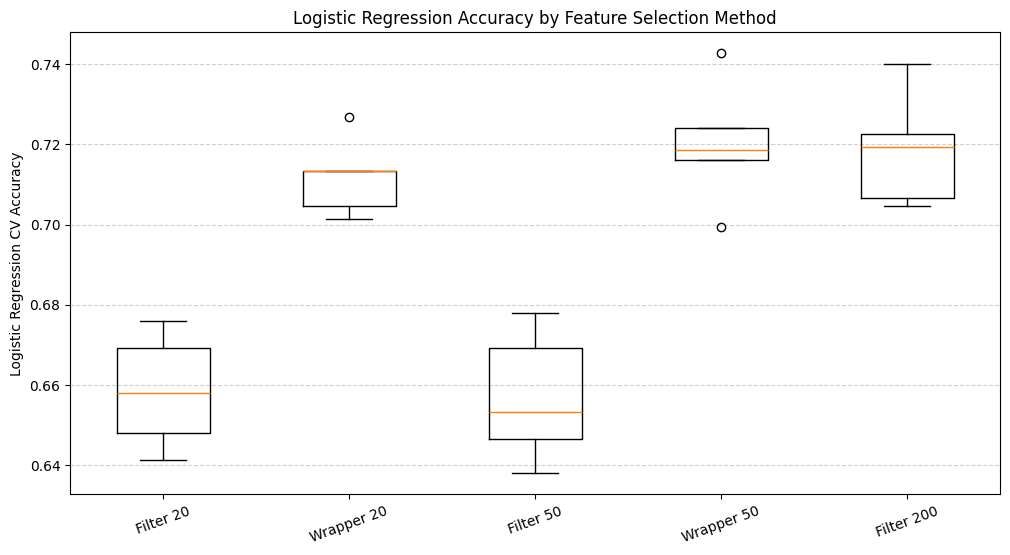

In [ ]:

from sklearn.model_selection import StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt

LR = LogisticRegression(max_iter=1000, penalty="l2", solver="lbfgs", random_state=42)

lr_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filtering_feature_counts = [20, 50, 200]
wrapper_feature_counts = [20, 50]


def most_frequent_features(feature_lists, n_features, original_space_size=64 * 64):
    feature_counts = np.zeros(original_space_size, dtype=int)
    for features in feature_lists:
        feature_counts[features] += 1
    return np.argsort(feature_counts)[-n_features:]


# Build stable feature sets from filtering results in original 64x64 space
filtering_selected_sets = {}
for k in filtering_feature_counts:
    filtering_selected_sets[k] = most_frequent_features(selected_features[k], k)

# Build stable feature sets from wrapper results in original 64x64 space
wrapper_selected_sets = {}
for n_features in wrapper_feature_counts:
    wrapper_counts = np.zeros(64 * 64, dtype=int)
    for run_idx, reduced_selected in enumerate(selected_features_wrapper[n_features]):
        mapping = feature_mappings[n_features][run_idx]
        original_selected = mapping[reduced_selected]
        wrapper_counts[original_selected] += 1
    wrapper_selected_sets[n_features] = np.argsort(wrapper_counts)[-n_features:] # get top n_features most frequently selected in original space


# Evaluate logistic regression with CV on each feature set
lr_results = {
    "Filtering": {},
    "Wrapper": {},
}


for k in filtering_feature_counts:
    fold_acc = []
    selected_idx = filtering_selected_sets[k]

    for train_idx, val_idx in lr_cv.split(X_train, y_train):
        X_tr = X_train[train_idx][:, selected_idx]
        X_val = X_train[val_idx][:, selected_idx]
        y_tr = y_train[train_idx]
        y_val = y_train[val_idx]

        LR.fit(X_tr, y_tr)
        fold_acc.append(LR.score(X_val, y_val))

    lr_results["Filtering"][k] = fold_acc
    print(f"Filtering {k} features: mean LR CV accuracy = {np.mean(fold_acc):.4f}")

for n_features in wrapper_feature_counts:
    fold_acc = []
    selected_idx = wrapper_selected_sets[n_features]

    for train_idx, val_idx in lr_cv.split(X_train, y_train):
        X_tr = X_train[train_idx][:, selected_idx]
        X_val = X_train[val_idx][:, selected_idx]
        y_tr = y_train[train_idx]
        y_val = y_train[val_idx]

        LR.fit(X_tr, y_tr)
        fold_acc.append(LR.score(X_val, y_val))

    lr_results["Wrapper"][n_features] = fold_acc
    print(f"Wrapper {n_features} features: mean LR CV accuracy = {np.mean(fold_acc):.4f}")


# Boxplot comparison
boxplot_data = [
    lr_results["Filtering"][20],
    lr_results["Wrapper"][20],
    lr_results["Filtering"][50],
    lr_results["Wrapper"][50],
    lr_results["Filtering"][200],
]
labels = [
    "Filter 20",
    "Wrapper 20",
    "Filter 50",
    "Wrapper 50",
    "Filter 200",
]

plt.figure(figsize=(12, 6))
plt.boxplot(boxplot_data, labels=labels, showmeans=False)
plt.ylabel("Logistic Regression CV Accuracy")
plt.title("Logistic Regression Accuracy by Feature Selection Method")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.xticks(rotation=20)
plt.show()


/var/folders/hn/3_40yr6s0bx280zl0j62jsvm0000gn/T/ipykernel_46067/3508261274.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(boxplot_data, labels=labels, showmeans=True)


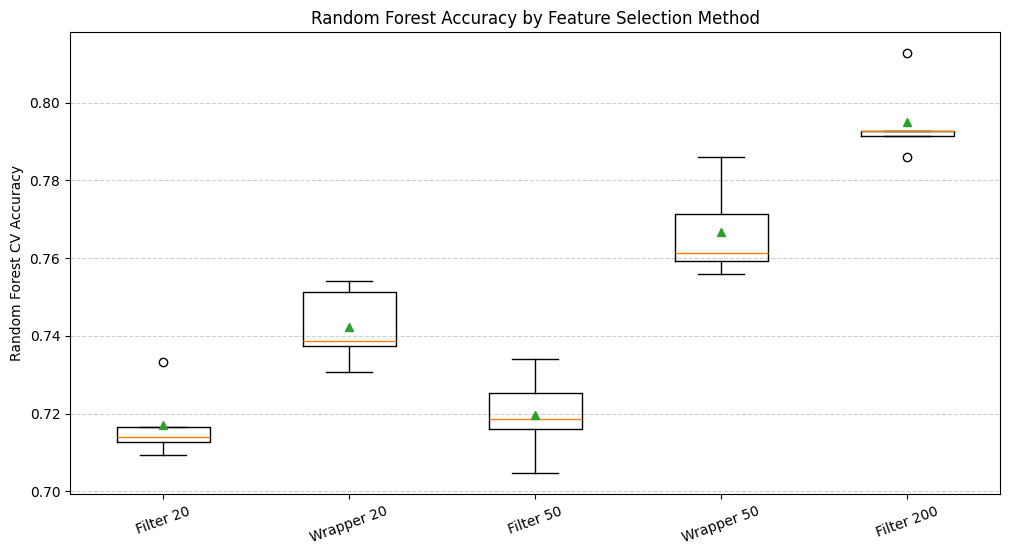

In [ ]:
# Boxplot comparison
boxplot_data = [
    rf_results["Filtering"][20],
    rf_results["Wrapper"][20],
    rf_results["Filtering"][50],
    rf_results["Wrapper"][50],
    rf_results["Filtering"][200],
]
labels = [
    "Filter 20",
    "Wrapper 20",
    "Filter 50",
    "Wrapper 50",
    "Filter 200",
]

plt.figure(figsize=(12, 6))
plt.boxplot(boxplot_data, labels=labels, showmeans=True)
plt.ylabel("Random Forest CV Accuracy")
plt.title("Random Forest Accuracy by Feature Selection Method")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.xticks(rotation=20)
plt.show()

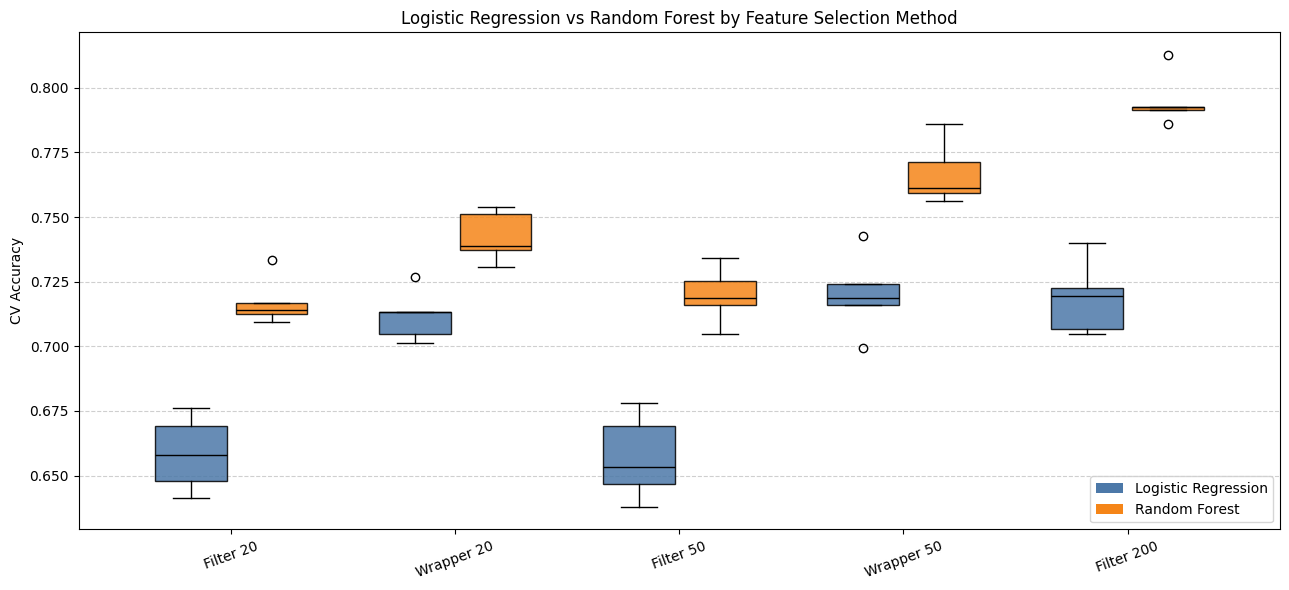

In [ ]:
# Combined boxplot comparison: Logistic Regression vs Random Forest
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

feature_labels = ["Filter 20", "Wrapper 20", "Filter 50", "Wrapper 50", "Filter 200"]
positions = np.arange(1, len(feature_labels) + 1)
offset = 0.18
box_width = 0.32

lr_boxplot_data = [
    lr_results["Filtering"][20],
    lr_results["Wrapper"][20],
    lr_results["Filtering"][50],
    lr_results["Wrapper"][50],
    lr_results["Filtering"][200],
]

rf_boxplot_data = [
    rf_results["Filtering"][20],
    rf_results["Wrapper"][20],
    rf_results["Filtering"][50],
    rf_results["Wrapper"][50],
    rf_results["Filtering"][200],
]

fig, ax = plt.subplots(figsize=(13, 6))

lr_bp = ax.boxplot(
    lr_boxplot_data,
    positions=positions - offset,
    widths=box_width,
    patch_artist=True,
    showmeans=False,
    medianprops={"color": "black"},
)
rf_bp = ax.boxplot(
    rf_boxplot_data,
    positions=positions + offset,
    widths=box_width,
    patch_artist=True,
    showmeans=False,
    medianprops={"color": "black"},
)

for patch in lr_bp["boxes"]:
    patch.set_facecolor("#4C78A8")
    patch.set_alpha(0.85)

for patch in rf_bp["boxes"]:
    patch.set_facecolor("#F58518")
    patch.set_alpha(0.85)

ax.set_xticks(positions)
ax.set_xticklabels(feature_labels, rotation=20)
ax.set_ylabel("CV Accuracy")
ax.set_title("Logistic Regression vs Random Forest by Feature Selection Method")
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.legend(
    handles=[
        Patch(facecolor="#4C78A8", label="Logistic Regression"),
        Patch(facecolor="#F58518", label="Random Forest"),
    ],
    loc="lower right",
)

plt.tight_layout()
plt.show()


In [ ]:
# In the last project we have already seen example of the MNIST data set. Here we take a look at Cats and Dogs

import pandas as pd 

PATHIM = "cnd_large//images.csv" 
PATHLB = "cnd_large//labels.csv"

images = pd.read_csv(PATHIM, sep=",", index_col=0)
labels = pd.read_csv(PATHLB, sep=",", index_col=0)

labels = labels.rename(columns={"0":"label"})

# Check sizes
print(f"'images' size: {images.shape}")
print(f"'labels' size: {labels.shape}")

# Number of classes:
#print(f"Classes {labels["label"].unique()}")

'images' size: (10000, 4096)
'labels' size: (10000, 1)


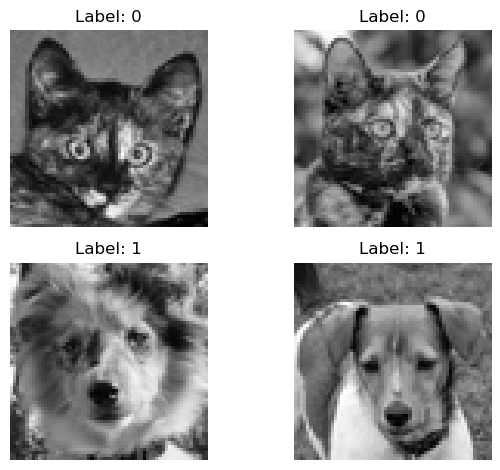

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

images = np.array(images)
labels = np.array(labels).ravel()

#Visualize some images (take two from each class):
catidx = np.where(labels == 0)[0]
dogidx = np.where(labels == 1)[0]

n_samples = 2

catsample = np.random.choice(catidx, size = n_samples, replace = False)
dogsample = np.random.choice(dogidx, size = n_samples, replace = False)

idx = np.concatenate([catsample, dogsample])
images_sub = images[idx]
labels_sub = labels[idx]

fig, axes = plt.subplots(2, 2)

for i, ax in enumerate(axes.ravel()):
    img = images_sub[i].reshape(64,64)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {labels_sub[i]}")
    ax.axis("off")

plt.tight_layout()

In [ ]:
import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = images
y = labels

# Fixed train/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

n_train_full = X_train_full.shape[0]
fractions = np.linspace(1.0, 0.1, 10)

results = { "svd": [], "shrink": [] }
rng = np.random.RandomState(0)

for f in fractions:
    n_keep = int(n_train_full * f)
    idx = rng.choice(n_train_full, n_keep, replace=False)
    X_train = X_train_full[idx]
    y_train = y_train_full[idx]

    # SVD solver (fastest)
    try:
        acc_svd = accuracy_score(y_test,
            LinearDiscriminantAnalysis(solver="svd").fit(X_train, y_train).predict(X_test)
        )
    except:
        acc_svd = np.nan

    # Regularized / shrunk LDA (fast, avoids singularity)
    try:
        acc_shrink = accuracy_score(y_test,
            LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
            .fit(X_train, y_train)
            .predict(X_test)
        )
    except:
        acc_shrink = np.nan

    results["svd"].append((f, acc_svd))
    results["shrink"].append((f, acc_shrink))

# Print
for name in results:
    print(f"\n== {name} ==")
    for f, acc in results[name]:
        print(f"Fraction {f:.2f}: acc = {acc:.3f}")


== svd ==
Fraction 1.00: acc = 0.689
Fraction 0.90: acc = 0.670
Fraction 0.80: acc = 0.648
Fraction 0.70: acc = 0.606
Fraction 0.60: acc = 0.545
Fraction 0.50: acc = 0.599
Fraction 0.40: acc = 0.660
Fraction 0.30: acc = 0.674
Fraction 0.20: acc = 0.723
Fraction 0.10: acc = 0.738

== shrink ==
Fraction 1.00: acc = 0.756
Fraction 0.90: acc = 0.746
Fraction 0.80: acc = 0.745
Fraction 0.70: acc = 0.747
Fraction 0.60: acc = 0.733
Fraction 0.50: acc = 0.728
Fraction 0.40: acc = 0.729
Fraction 0.30: acc = 0.710
Fraction 0.20: acc = 0.726
Fraction 0.10: acc = 0.730


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Custom transformer for global standard scaling
class GlobalStandardScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.mean_ = X.mean()
        self.std_ = X.std()
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_
    

# Pipeline
pipeline = Pipeline([
    ('scaler', GlobalStandardScaler()),
    ('classifier', LogisticRegression(
        penalty='elasticnet',
        solver='saga', # Allows for elastic net regularization
        max_iter=4000,
    ))
])

# Parameter grid to test for hyperparameter tuning
param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1], # Tunes the strength of the regularizer
    'classifier__l1_ratio': [0.1, 0.25, 0.5, 0.75, 0.9], # Elastic net l1/l2 ratio tuning
}

# 5-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

# Pipeline train with cv
grid_search.fit(X_train, y_train)

print("Best Parameters:\n", grid_search.best_params_)
print("\nBest CV Score:", grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END .....classifier__C=0.001, classifier__l1_ratio=0.25; total time=   0.0s
[CV] END .....classifier__C=0.001, classifier__l1_ratio=0.25; total time=   0.0s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.1; total time=   0.2s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.1; total time=   0.1s
[CV] END .....classifier__C=0.001, classifier__l1_ratio=0.25; total time=   0.0s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.5; total time=   0.1s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.1; total time=   0.2s
[CV] END .....classifier__C=0.001, classifier__l1_ratio=0.25; total time=   0.1s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.5; total time=   0.0s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.5; total time=   0.0s
[CV] END ......classifier__C=0.001, classifier__l1_ratio=0.5; total time=   0.0s
[CV] END ......classifier__C=0.001, classifier_

/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END ..........classifier__C=1, classifier__l1_ratio=0.5; total time= 1.8min


/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END ..........classifier__C=1, classifier__l1_ratio=0.5; total time= 1.8min


/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (19 outputs left out)

/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END ..........classifier__C=1, classifier__l1_ratio=0.9; total time= 1.4min


/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END ..........classifier__C=1, classifier__l1_ratio=0.9; total time= 1.3min
Best Parameters:
 {'classifier__C': 0.1, 'classifier__l1_ratio': 0.25}

Best CV Score: 0.8142857142857144


In [ ]:
# Now looking at the 5-fold CV results for hyperparameter tuning

results = pd.DataFrame(grid_search.cv_results_)

# Extract individual fold scores
fold_columns = [
    'split0_test_score',
    'split1_test_score',
    'split2_test_score',
    'split3_test_score',
    'split4_test_score'
]

# Create df for plotting
records = []

for _, row in results.iterrows():
    C_value = row['param_classifier__C']
    l1_value = row['param_classifier__l1_ratio']

    for fold_col in fold_columns:
        records.append({
            'C': float(C_value),
            'l1_ratio': float(l1_value),
            'accuracy': row[fold_col]
        })

cv_scores_df = pd.DataFrame(records)



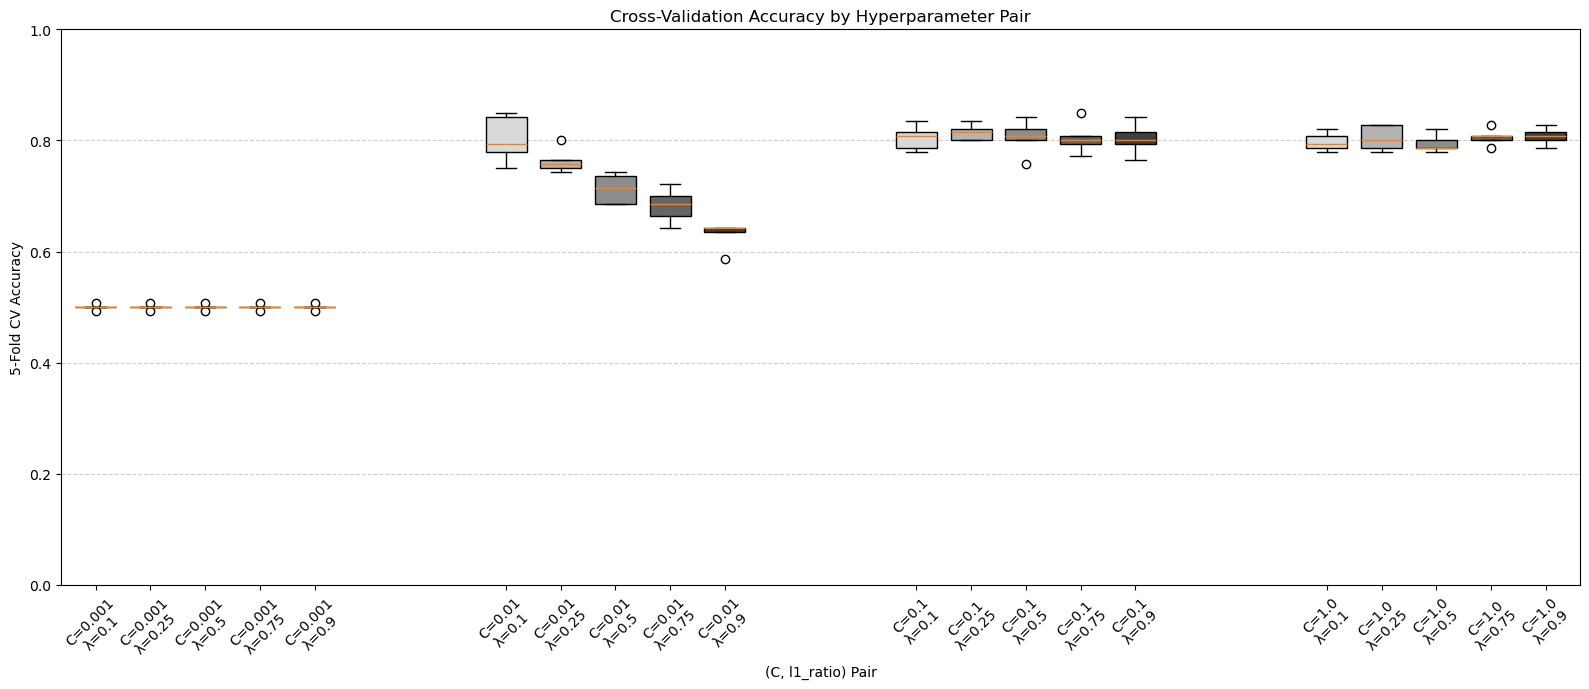

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# Unique hyperparameter values
# ---------------------------------------------------
C_values = sorted(cv_scores_df['C'].unique())
l1_values = sorted(cv_scores_df['l1_ratio'].unique())

# ---------------------------------------------------
# Create grouped data + positions
# ---------------------------------------------------
grouped_data = []
positions = []
labels = []
colors = []

# Spacing controls
within_group_spacing = 0.8
between_group_spacing = 2.0

current_position = 1

# Use grayscale shades for l1_ratio
# smaller l1_ratio = lighter
# larger l1_ratio = darker
shade_map = np.linspace(0.85, 0.25, len(l1_values))

for C_val in C_values:

    for i, l1_val in enumerate(l1_values):

        # Extract scores
        scores = cv_scores_df[
            (cv_scores_df['C'] == C_val) &
            (cv_scores_df['l1_ratio'] == l1_val)
        ]['accuracy']

        grouped_data.append(scores)

        positions.append(current_position)

        labels.append(f'C={C_val}\nλ={l1_val}')

        colors.append(str(shade_map[i]))

        current_position += within_group_spacing

    # Add extra spacing between different C groups
    current_position += between_group_spacing

# ---------------------------------------------------
# Create figure
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 7))

bp = ax.boxplot(
    grouped_data,
    positions=positions,
    patch_artist=True,
    widths=0.6
)

# ---------------------------------------------------
# Color boxes by l1_ratio shade
# ---------------------------------------------------
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

# ---------------------------------------------------
# Formatting
# ---------------------------------------------------
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=45)

ax.set_xlabel("(C, l1_ratio) Pair")
ax.set_ylabel("5-Fold CV Accuracy")
ax.set_title("Cross-Validation Accuracy by Hyperparameter Pair")

# Force y-axis to [0,1]
ax.set_ylim(0, 1)

# Add light horizontal grid
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# Evaluating the best model

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred)) # 0.789 accuracy
print("\nClassification Report:\n", classification_report(y_test, y_pred))

"""
# Evaluating on a different model with less regularization 
selected_model = Pipeline([
    ('scaler', GlobalStandardScaler()),
    ('classifier', LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        max_iter=2000,
        n_jobs=-1,
        C=1.0,
        l1_ratio=0.25
    ))
])

# Train on full training set
selected_model.fit(X_train, y_train)

y_pred = selected_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred)) #0.777 accuracy
print("\nClassification Report:\n", classification_report(y_test, y_pred))
"""

Test Accuracy: 0.7893333333333333

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.80      0.79      1500
           1       0.80      0.77      0.79      1500

    accuracy                           0.79      3000
   macro avg       0.79      0.79      0.79      3000
weighted avg       0.79      0.79      0.79      3000



'\n# Evaluating on a different model with less regularization \nselected_model = Pipeline([\n    (\'scaler\', GlobalStandardScaler()),\n    (\'classifier\', LogisticRegression(\n        penalty=\'elasticnet\',\n        solver=\'saga\',\n        max_iter=2000,\n        n_jobs=-1,\n        C=1.0,\n        l1_ratio=0.25\n    ))\n])\n\n# Train on full training set\nselected_model.fit(X_train, y_train)\n\ny_pred = selected_model.predict(X_test)\n\nprint("Test Accuracy:", accuracy_score(y_test, y_pred)) #0.777 accuracy\nprint("\nClassification Report:\n", classification_report(y_test, y_pred))\n'

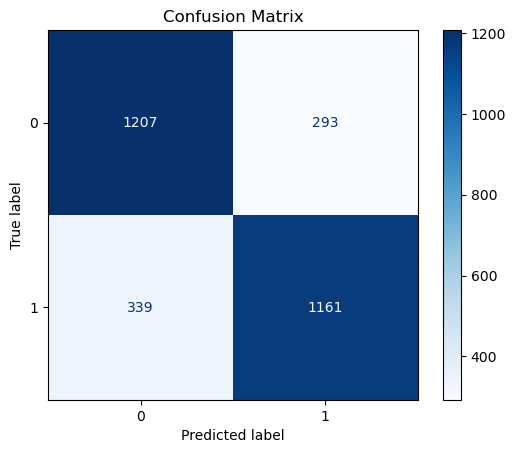

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Extract trained classifier
clf = best_model.named_steps['classifier']

# Coefficients: shape = (n_classes, n_features)
coefs = clf.coef_

# Aggregate across classes 
importance = np.mean(np.abs(coefs), axis=0)

print("Total features:", importance.shape[0])
print("Non-zero (selected) features:", np.sum(importance > 1e-6)) #634 pixels selected for C=0.1, 2086 for C=1


Total features: 4096
Non-zero (selected) features: 634


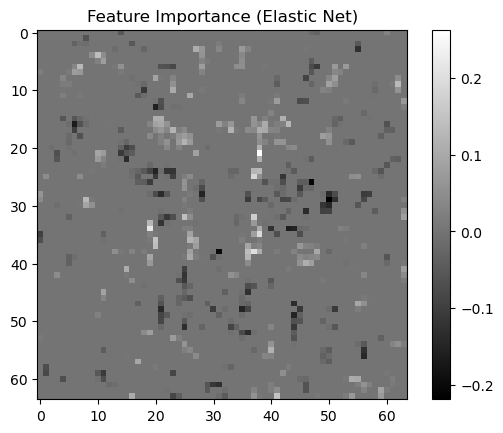

In [ ]:
# Reshape into image
image = coefs.reshape(64, 64)

plt.figure()
plt.imshow(image, cmap='gray')
plt.colorbar()
plt.title("Feature Importance (Elastic Net)")
plt.show()

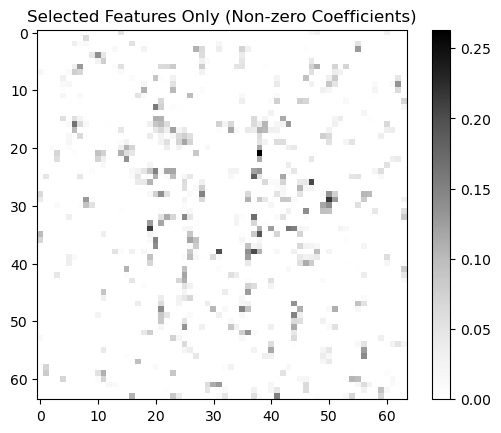

In [ ]:
# Mask for selected features
mask = importance > 1e-6

selected_only = np.zeros_like(importance)
selected_only[mask] = importance[mask]

image_selected = selected_only.reshape(64, 64)

plt.figure()
plt.imshow(image_selected, cmap='Greys')
plt.colorbar()
plt.title("Selected Features Only (Non-zero Coefficients)")
plt.show()

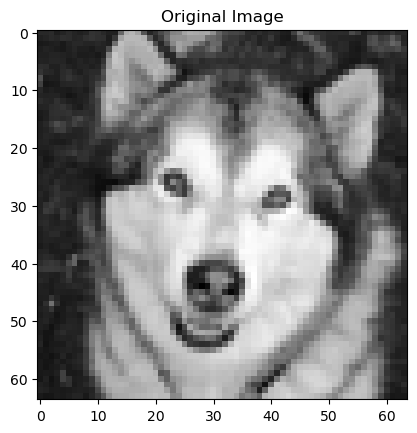

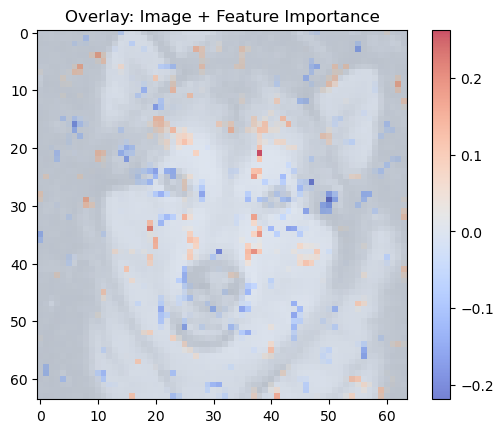

In [ ]:
# Show one original image
sample_img = X_test[3].reshape(64, 64)

plt.figure()
plt.imshow(sample_img, cmap='gray')
plt.title("Original Image")
plt.show()

# Overlay importance
plt.figure()
plt.imshow(sample_img, cmap='gray', alpha=0.5)
plt.imshow(image, cmap='coolwarm', alpha=0.7)
plt.colorbar()
plt.title("Overlay: Image + Feature Importance")
plt.show()

In [ ]:
import numpy as np

# Reproducibility
rng = np.random.default_rng(seed=42)

# Copy original training data
X_train_noisy = X_train.astype(float).copy()

n_features = X_train.shape[1]          
noise_fraction = 0.2                     # noise added to 20% randomly selected pixels
n_noisy_features = int(n_features * noise_fraction)

# Standard deviation of Gaussian noise
noise_std = 40

# Same features selected for each individual image
noisy_feature_indices = rng.choice(
    n_features,
    size=n_noisy_features,
    replace=False
)

    
noise = rng.normal(
    loc=0.0,                 # mean
    scale=noise_std,         # standard deviation
    size=(X_train.shape[0], n_noisy_features)
)

X_train_noisy[:, noisy_feature_indices] += noise

X_train_noisy = np.clip(X_train_noisy, 0, 255) # Keeping the pixel values between [0, 255]



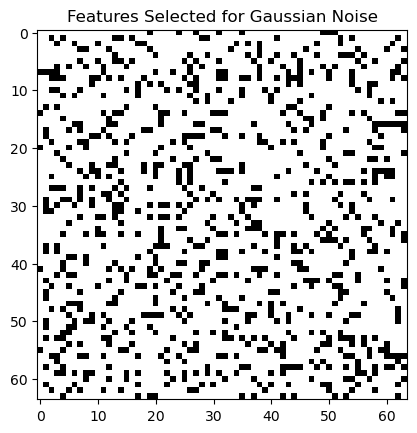

In [ ]:
import matplotlib.pyplot as plt

# Looking at the features selected for noise
mask = np.zeros(n_features)
mask[noisy_feature_indices] = 1

mask_image = mask.reshape(64, 64)

plt.figure()
plt.imshow(mask_image, cmap='Greys')
plt.title("Features Selected for Gaussian Noise")
plt.show()

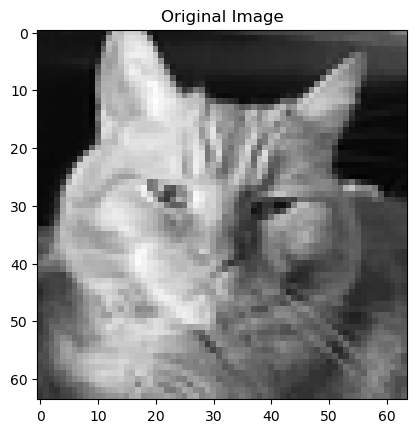

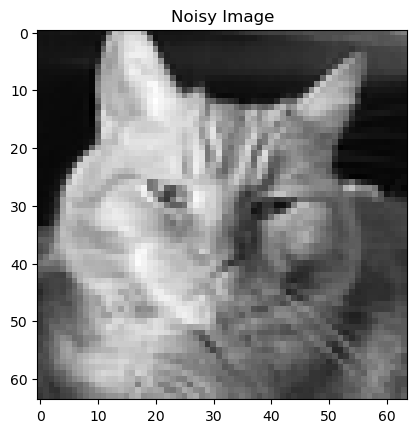

In [ ]:
# Comparing original image to noisy  one

idx = 0

original = X_train[idx].reshape(64, 64)
noisy = X_train_noisy[idx].reshape(64, 64)

plt.figure()
plt.imshow(original, cmap='gray')
plt.title("Original Image")
plt.show()

plt.figure()
plt.imshow(noisy, cmap='gray')
plt.title("Noisy Image")
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone


rng = np.random.default_rng(seed=42)


noise_fractions = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
noise_std = 50

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


pipeline = Pipeline([
    ('scaler', GlobalStandardScaler()),

    ('classifier', LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        C=0.1,
        l1_ratio=0.25,
        max_iter=2000,
        n_jobs=-1
    ))
])

results = []

n_features = X_train.shape[1]

# Loop through noise fractions
for noise_fraction in noise_fractions:

    X_train_noisy = X_train.astype(float).copy()

    n_noisy_features = int(n_features * noise_fraction)

    # Select SAME noisy features for all images
    noisy_feature_indices = rng.choice(
        n_features,
        size=n_noisy_features,
        replace=False
    )

    noise = rng.normal(
        loc=0.0, 
        scale=noise_std,
        size=(X_train.shape[0], n_noisy_features)
    )

    X_train_noisy[:, noisy_feature_indices] += noise

    # Keep pixel range valid
    X_train_noisy = np.clip(X_train_noisy, 0, 255)

    # Fitting pipeline on noisy data
    cv_scores = cross_val_score(
        pipeline,
        X_train_noisy,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    mean_cv_accuracy = np.mean(cv_scores)


    fitted_pipeline = clone(pipeline)
    fitted_pipeline.fit(X_train_noisy, y_train)
    clf = fitted_pipeline.named_steps['classifier']

    # Looking at coefficients
    coefs = clf.coef_
    importance = np.mean(np.abs(coefs), axis=0)
    n_selected_features = np.sum(importance > 1e-6)

    # Testing on test set
    y_pred = fitted_pipeline.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'noise_fraction': noise_fraction,
        'mean_cv_accuracy': mean_cv_accuracy,
        'num_selected_features': n_selected_features,
        'test_accuracy': test_accuracy
    })

results_df = pd.DataFrame(results)

print("\nResults Summary:")
print(results_df)



Results Summary:
   noise_fraction  mean_cv_accuracy  num_selected_features  test_accuracy
0            0.25          0.778571                    616       0.788000
1            0.50          0.770000                    611       0.783333
2            0.75          0.791429                    592       0.794667
3            0.90          0.794286                    634       0.795000
4            0.95          0.768571                    619       0.797667
5            0.99          0.782857                    618       0.791333


/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


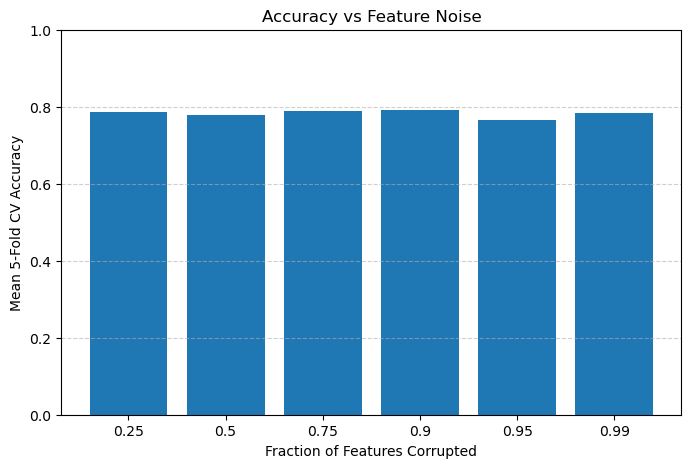

In [ ]:
# Plotting accuracy vs noise fraction

import matplotlib.pyplot as plt

# Convert x labels to strings for cleaner bars
x_labels = [str(x) for x in results_df['noise_fraction']]

plt.figure(figsize=(8, 5))

plt.bar(
    x_labels,
    results_df['mean_cv_accuracy']
)

plt.xlabel("Fraction of Features Corrupted")
plt.ylabel("Mean 5-Fold CV Accuracy")
plt.title("Accuracy vs Feature Noise")

plt.ylim(0, 1)

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

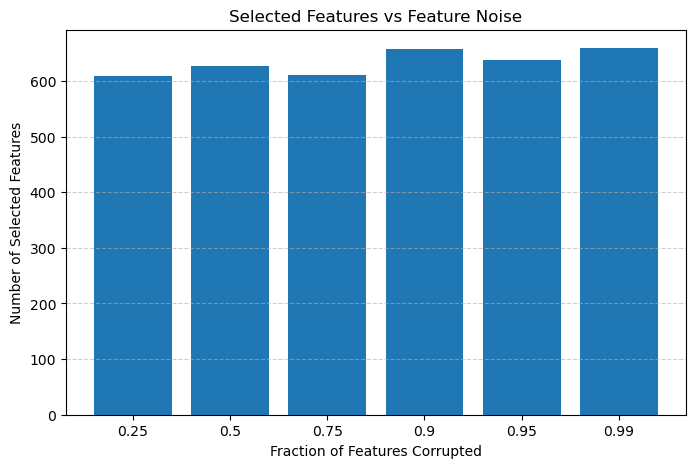

In [ ]:
# Fraction of features vs noise fraction

plt.figure(figsize=(8, 5))

plt.bar(
    x_labels,
    results_df['num_selected_features']
)

plt.xlabel("Fraction of Features Corrupted")
plt.ylabel("Number of Selected Features")
plt.title("Selected Features vs Feature Noise")

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
# Using Gabriel's code for dependent noise
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

seed=42

# Custom transformer for global standard scaling
class GlobalStandardScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.mean_ = X.mean()
        self.std_ = X.std()
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

from scipy.ndimage import gaussian_filter

def analysis_pipeline(images, labels, pipe, param_grid, noise=None, noise_level=0, heatmap=False, seed=42):

    output = {}

    # (OPTIONAL) Corrupt a fraction of pixels with Gaussian noise
    if noise_level > 0 and noise is not None:
        rng = np.random.default_rng(seed)
        n_features = images.shape[1]
        side       = int(np.sqrt(n_features))
        n_noisy    = int(round(noise_level * n_features))
        noise_idx  = rng.choice(n_features, size=n_noisy, replace=False)
        images     = images.astype(float, copy=True)
        sigma      = images.std()

        if noise == "independent":
            ind_noise = rng.normal(0, sigma, size=(images.shape[0], n_noisy))
            images[:, noise_idx] += ind_noise
            images = np.clip(images, 0, 255) # making sure the pixel values are within [0, 255]

            # Pure noise pattern: one image's worth of noise, zeros elsewhere
            pure = np.zeros(n_features)
            pure[noise_idx] = ind_noise[0]
            output["noise_pattern"] = pure.reshape(side, side)

        elif noise == "dependent":
            raw    = rng.normal(0, sigma, size=(images.shape[0], side, side))
            smooth = gaussian_filter(raw, sigma=(0, 2, 2))
            smooth *= sigma / smooth.std()
            smooth_flat = smooth.reshape(images.shape[0], -1)
            images[:, noise_idx] += smooth_flat[:, noise_idx]
            images = np.clip(images, 0, 255) # making sure the pixel values are within [0, 255]


            # Pure noise pattern: one image's worth of noise, zeros elsewhere
            pure = np.zeros(n_features)
            pure[noise_idx] = smooth_flat[0][noise_idx]
            output["noise_pattern"] = pure.reshape(side, side)

        # Capture a noisy image (after noise has been applied)
        output["sample_noisy_image"] = images[0].reshape(side, side)

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(output["noise_pattern"], cmap='gray')
        axes[0].set_title('Noise pattern')
        axes[0].axis('off')
        axes[1].imshow(output["sample_noisy_image"], cmap='gray')
        axes[1].set_title('Example noisy image')
        axes[1].axis('off')
        fig.suptitle(f"{noise.capitalize()} noise applied to {100*noise_level:.0f}% of pixels", fontsize=16)
        plt.show()

    # ------------------------------------------------------------------------------

    # 1. Create a test and train set
    X_train, X_test, y_train, y_test = train_test_split(images, labels, 
                                                        random_state=seed, test_size=0.25, stratify=labels)

    # ------------------------------------------------------------------------------
    # 2. Define the CV splitting strategy
    fixed_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # ------------------------------------------------------------------------------

    # 3. Run Cross-Validation and fit best model
    # grid = GridSearchCV(pipe, param_grid, cv=fixed_cv, scoring='f1_macro', n_jobs=1) # For cases where we basically don't have a grid search
    grid = GridSearchCV(pipe, param_grid, cv=fixed_cv, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    # -----------------------------------------------------------------------------
    
    # 4. Evaluate the best model on the test set
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    output["best_params"] = grid.best_params_
    output["best_model"] = best_model
    output["cv_score"] = grid.best_score_
    output["test_f1_macro"] = f1_score(y_test, y_pred, average='macro')
    output["test_accuracy"] = accuracy_score(y_test, y_pred)
    output["y_test"] = y_test
    output["y_pred"] = y_pred
    
    print(3)
    # --- (OPTIONAL) Track pixel selection frequency across folds ---
    if heatmap:
        cv_results = cross_validate(
            grid.best_estimator_, X_train, y_train,
            cv=fixed_cv, return_estimator=True, n_jobs=-1,
        )

        n_pixels = X_train.shape[1]
        selection_counts = np.zeros(n_pixels)

        for est in cv_results['estimator']:
            try:
                filter_idx = np.where(est.named_steps['filter'].get_support())[0]
            except:
                filter_idx = np.arange(X_train.shape[1])  # If no filter step, use all features
            try:
                embedding_idx  = filter_idx[est.named_steps['embedding'].get_support()]
            except:
                embedding_idx = filter_idx  # If no embedding step, use filter indices directly
            try:
                clf_idx = embedding_idx[est.named_steps['clf'].coef_[0] != 0]
            except:
                clf_idx = embedding_idx  # If no clf step, use embedding indices directly
            selection_counts[clf_idx] += 1


        selection_freq = selection_counts / fixed_cv.n_splits
        heatmap = selection_freq.reshape(int(np.sqrt(n_pixels)), -1)

        output['pixel_selection_frequency'] = selection_freq
        output['avg_selected_pixels'] = selection_freq.sum()

        plt.imshow(heatmap, cmap='hot', vmin=0, vmax=1)
        plt.colorbar(label='Selection frequency across folds')
        plt.title('Pixel selection frequency across CV folds')
        plt.axis('off')
        plt.show()
        print(f"Average number of pixels selected across folds: {output['avg_selected_pixels']:.2f}")


    return output

pipe_logistic = Pipeline([
    ('scaler', GlobalStandardScaler()),
    ('clf', 
        LogisticRegression(
            penalty='elasticnet',
            solver='saga',
            max_iter=2000,
            random_state=seed,
            n_jobs=-1)
    ),
])

param_grid_logistic = {
    'clf__C': [0.1],
    'clf__l1_ratio': [0.25]
}



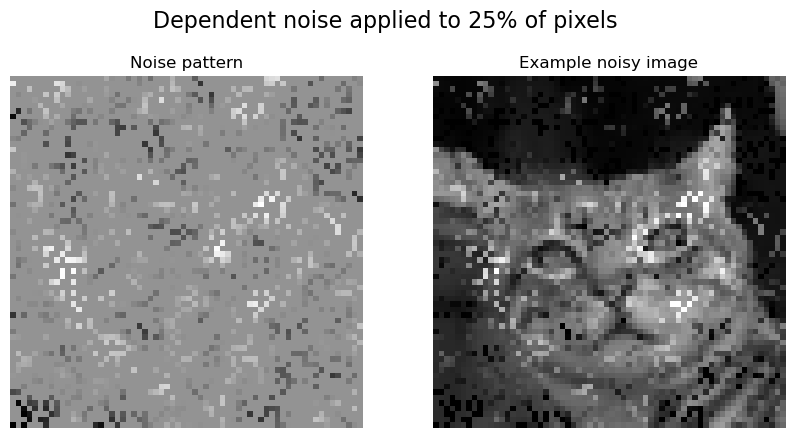

0
1
2
3


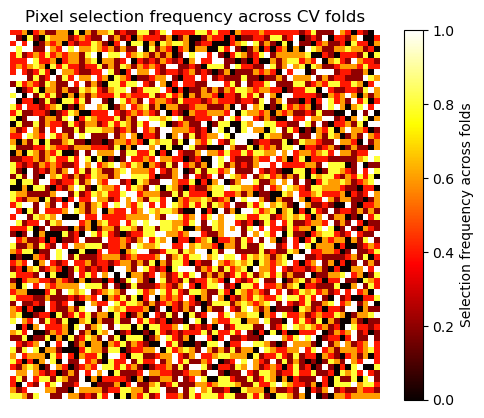

Average number of pixels selected across folds: 2014.40
Noise level: 0.25 - Test F1 Macro: 0.7980, Test Accuracy: 0.7980


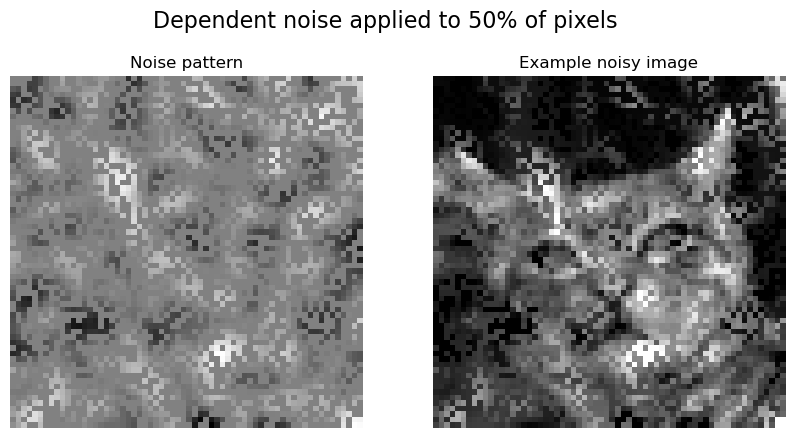

0
1
2
3


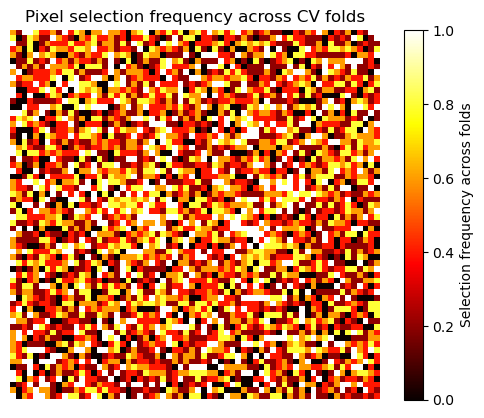

Average number of pixels selected across folds: 1990.80
Noise level: 0.5 - Test F1 Macro: 0.7956, Test Accuracy: 0.7956


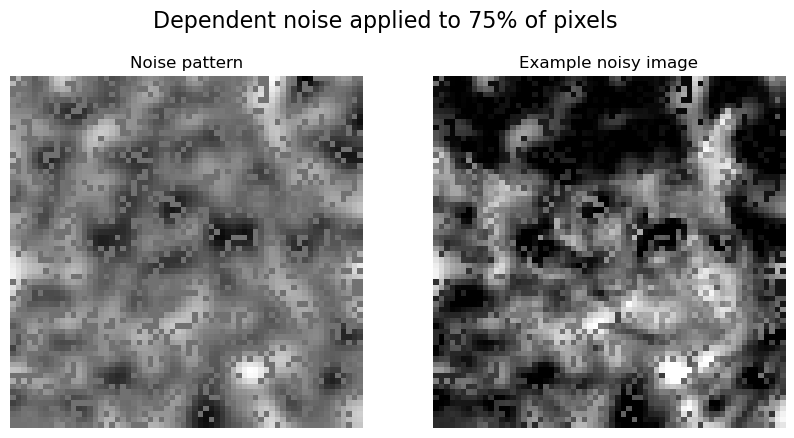

0
1
2
3


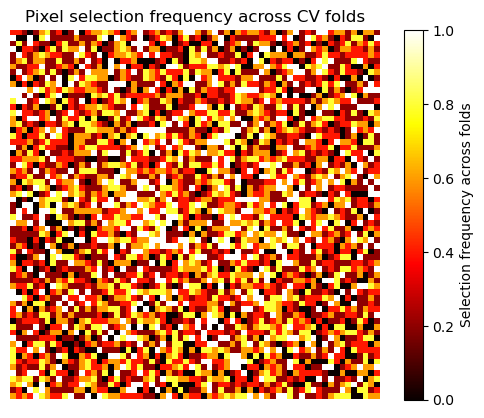

Average number of pixels selected across folds: 1951.20
Noise level: 0.75 - Test F1 Macro: 0.7916, Test Accuracy: 0.7916


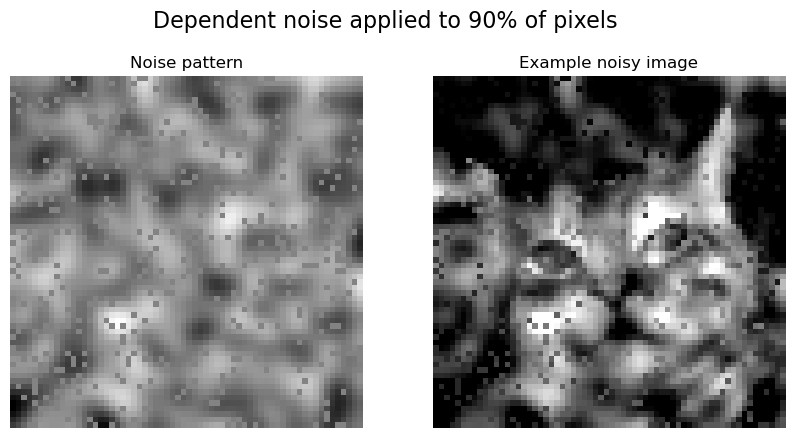

0
1
2
3


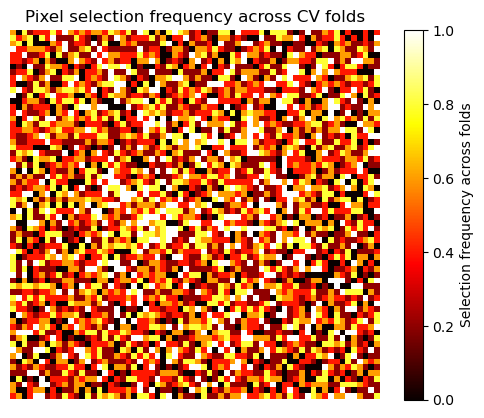

Average number of pixels selected across folds: 1908.80
Noise level: 0.9 - Test F1 Macro: 0.7864, Test Accuracy: 0.7864


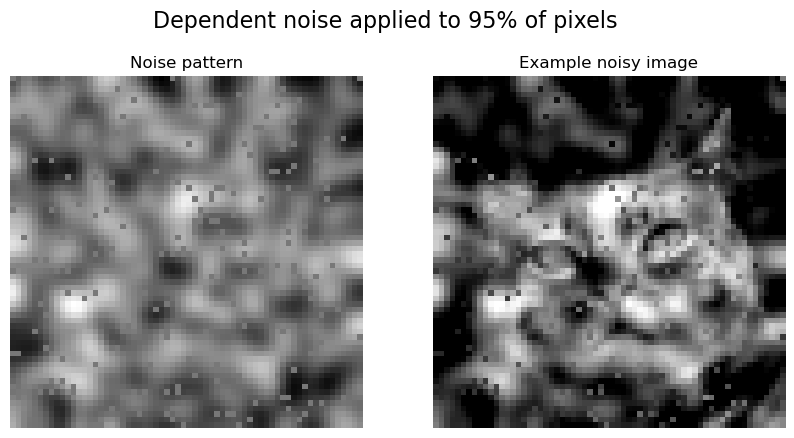

0
1
2
3


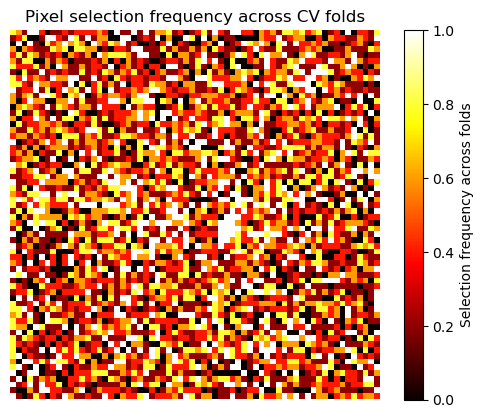

Average number of pixels selected across folds: 1915.80
Noise level: 0.95 - Test F1 Macro: 0.7782, Test Accuracy: 0.7784


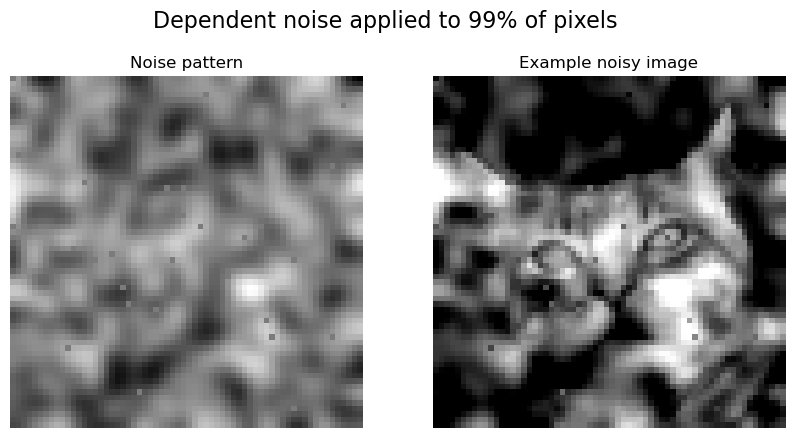

0
1
2
3


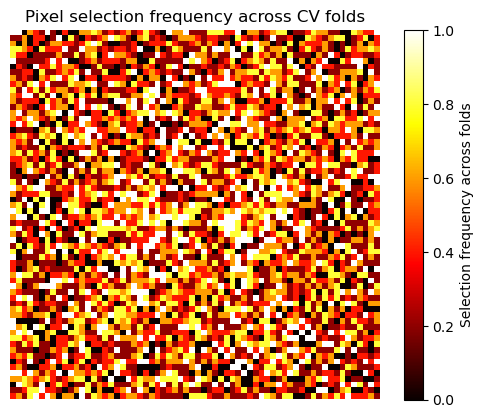

Average number of pixels selected across folds: 1956.40
Noise level: 0.99 - Test F1 Macro: 0.7520, Test Accuracy: 0.7520


In [ ]:

noise_levels = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]

for i in range(6):
    test = analysis_pipeline(X, y, pipe_logistic, param_grid_logistic, heatmap=True, noise="dependent", noise_level=noise_levels[i], seed=42)
    print(f"Noise level: {noise_levels[i]} - Test F1 Macro: {test['test_f1_macro']:.4f}, Test Accuracy: {test['test_accuracy']:.4f}")

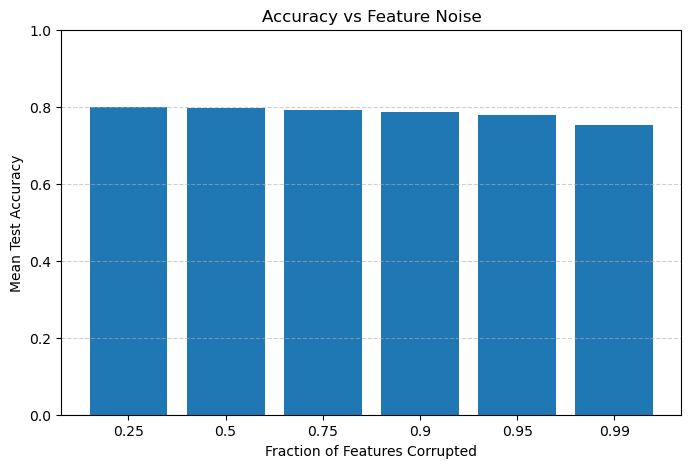

In [ ]:
#Results 

avg_num_pixels_selected = [2014, 1990, 1951, 1909, 1916, 1956]
accuracies = [0.798, 0.7956, 0.7916, 0.7864, 0.7784, 0.7520]

# Plotting accuracy vs noise fraction

import matplotlib.pyplot as plt

# Convert x labels to strings for cleaner bars
x_labels = [str(x) for x in noise_levels]

plt.figure(figsize=(8, 5))

plt.bar(
    x_labels,
    accuracies
)

plt.xlabel("Fraction of Features Corrupted")
plt.ylabel("Mean Test Accuracy")
plt.title("Accuracy vs Feature Noise")

plt.ylim(0, 1)

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

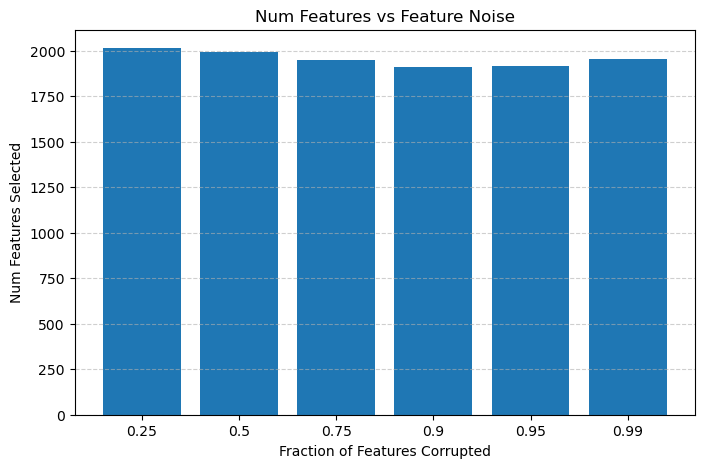

In [ ]:
# Plotting num_pixels_selected vs noise fraction

import matplotlib.pyplot as plt

# Convert x labels to strings for cleaner bars
x_labels = [str(x) for x in noise_levels]

plt.figure(figsize=(8, 5))

plt.bar(
    x_labels,
    avg_num_pixels_selected
)

plt.xlabel("Fraction of Features Corrupted")
plt.ylabel("Num Features Selected")
plt.title("Num Features vs Feature Noise")

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()